<div style="padding:28px;border-radius:16px;background:linear-gradient(120deg,#102a43,#216e82);color:white">
<div style="font-size:13px;letter-spacing:3px">МАТЕМАТИКА ДЛЯ ПРОГРАММИСТОВ · ЛИСТОК 2</div>
<h1 style="color:white;margin:12px 0">Комплексные числа: от первых формул до фракталов</h1>
<div style="font-size:17px">Подробная теория • пошаговые решения • вычисления • геометрия</div>
</div>

Этот ноутбук разбирает **все задания 2.1–2.10, включая задания со звёздочкой** из листка «Комплексные числа. Геометрия комплексных чисел» (составитель П. Е. Рябов). В исходнике номер **2.10** встречается дважды: здесь это **2.10-I: кривые** и **2.10-II: спираль**.

**Как читать.** Сначала пройдите теорию: она объясняет обозначения, смысл формул и необходимые алгоритмы. Затем в каждом задании читайте условие → рассуждение → ответ → код и рисунок. Графики уже сохранены внутри файла; для просмотра запуск Python не нужен. Для изменения параметров выполните **Restart Kernel and Run All Cells**. Все углы в коде заданы в радианах.

**Навигация:** [настройка](#setup) · [теория](#theory) · [2.1](#task21) · [2.2](#task22) · [2.3](#task23) · [2.4](#task24) · [2.5](#task25) · [2.6](#task26) · [2.7](#task27) · [2.8](#task28) · [2.9](#task29) · [2.10-I](#task210a) · [2.10-II](#task210b) · [итоги](#summary).

> **Два важных соглашения.** $\arg z=\operatorname{Arg}z+2\pi k$ обозначает все возможные углы, а $\operatorname{Arg}z\in(-\pi,\pi]$ — главный аргумент. В неравенствах задания 2.4 используем главный аргумент. У нуля аргумент не определён. В 2.4(e) интервал в исходном условии пуст; это отдельно разобрано без изменения условия.


<a id="setup"></a>
## Подготовка: библиотеки и оформление

`numpy` работает с массивами и комплексными числами, `matplotlib` рисует, `sympy` проверяет точную алгебру и корни с повышенной точностью, `scipy.special` вычисляет гамма-функцию. В Python мнимая единица записывается как `1j`, а степень — как `**`: например, `(1 + 1j)**2`.

Ноутбук сохраняет дополнительные PNG в папку `figures` рядом с файлом. Исходный PDF и подключение к интернету для выполнения не нужны.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Arc
from scipy.special import gamma, loggamma
import sympy as sp

FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'figure.facecolor': '#f7f9fc',
    'axes.facecolor': '#ffffff', 'axes.spines.top': False,
    'axes.spines.right': False, 'grid.color': '#cbd5e1',
    'grid.alpha': 0.45, 'figure.dpi': 115, 'savefig.dpi': 160,
})
BLUE, ORANGE, TEAL, RED = '#2864b7', '#e89b32', '#168b8a', '#c84555'

def plane(ax, title='', lim=None):
    ax.axhline(0, color='#64748b', lw=0.8)
    ax.axvline(0, color='#64748b', lw=0.8)
    ax.set(xlabel=r'$\operatorname{Re}z$', ylabel=r'$\operatorname{Im}z$', title=title)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(True, ls=':')
    if lim is not None:
        ax.set_xlim(*lim)
        ax.set_ylim(*lim)

def finish(fig, name):
    fig.savefig(FIGURES / f'{name}.png', bbox_inches='tight')
    plt.show()

def fmt(z, digits=6):
    z = complex(z)
    return f'{z.real:.{digits}f} {z.imag:+.{digits}f}i'

def all_roots(w, n):
    if w == 0:
        return np.zeros(n, dtype=complex)
    return abs(w)**(1/n) * np.exp(1j*(np.angle(w) + 2*np.pi*np.arange(n))/n)

print('Готово. Пример: (1 + i)^2 =', fmt((1 + 1j)**2))


Готово. Пример: (1 + i)^2 = 0.000000 +2.000000i


<a id="theory"></a>
# Часть I. Теория с нуля

## 1. Комплексное число — это точка и вектор

Действительных чисел недостаточно для решения $x^2=-1$. Вводят число $i$ со свойством $i^2=-1$ и рассматривают
$$z=x+iy,\qquad x,y\in\mathbb R.$$
Это **алгебраическая форма**. Числа $x=\operatorname{Re}z$ и $y=\operatorname{Im}z$ — координаты точки на плоскости. Например, $3+2i$ — точка $(3,2)$. Мнимая часть равна **2**, а не $2i$.

Сопряжение $\bar z=x-iy$ отражает точку относительно горизонтальной оси. Модуль
$$|z|=\sqrt{x^2+y^2}$$
равен расстоянию от начала координат. Более общо, $|z-a|$ — расстояние между точками $z$ и $a$. Поэтому $|z-a|=R$ задаёт окружность, $|z-a|<R$ — её внутренность, а равенство $|z-a|=|z-b|$ — серединный перпендикуляр к отрезку $ab$.

### Арифметика

Складываем координаты отдельно, а при умножении раскрываем скобки и заменяем $i^2$ на $-1$:
$$\begin{aligned}
(x+iy)+(u+iv)&=(x+u)+i(y+v),\\
(x+iy)(u+iv)&=(xu-yv)+i(xv+yu).
\end{aligned}$$

Для деления домножаем числитель и знаменатель на сопряжённый знаменатель:
$$\frac{x+iy}{u+iv}=\frac{(x+iy)(u-iv)}{u^2+v^2},\quad u+iv\ne0.$$
Знаменатель становится действительным, поскольку $w\bar w=|w|^2$. Например,
$$\frac{1+i}{1-i}=\frac{(1+i)^2}{2}=i.$$


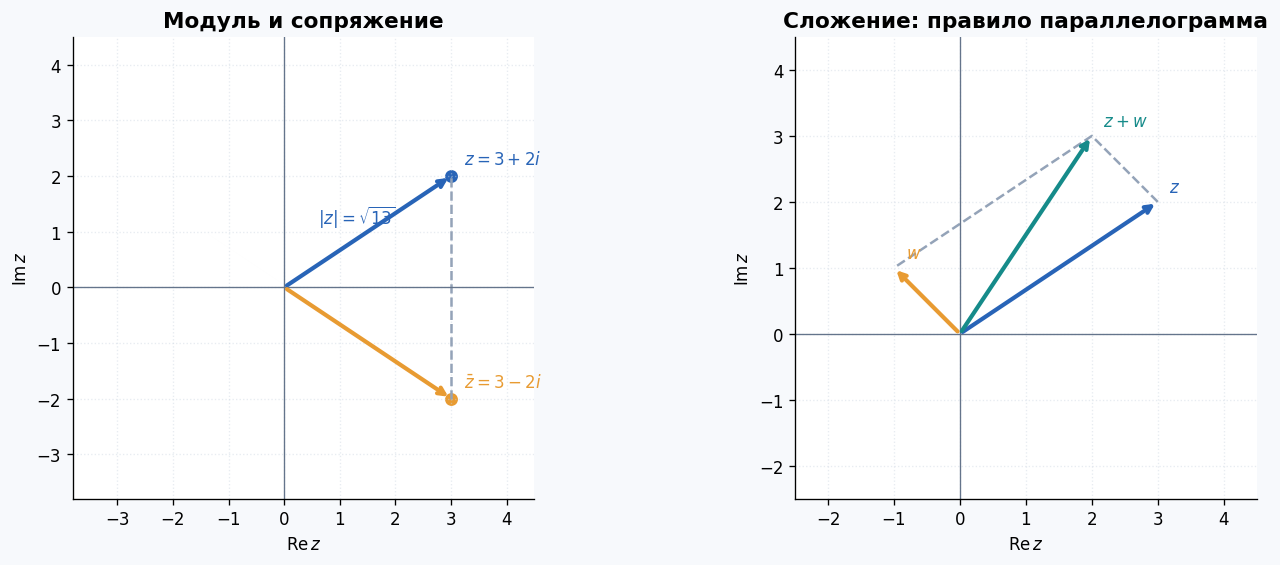

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
z, w = 3+2j, -1+1j
for value, label, color in [(z, '$z=3+2i$', BLUE), (z.conjugate(), r'$\bar z=3-2i$', ORANGE)]:
    axes[0].annotate('', (value.real, value.imag), (0, 0), arrowprops=dict(arrowstyle='->', color=color, lw=2.5))
    axes[0].scatter(value.real, value.imag, color=color, s=45)
    axes[0].annotate(label, (value.real, value.imag), xytext=(8, 7), textcoords='offset points', color=color)
axes[0].plot([z.real, z.real], [-2, 2], '--', color='#94a3b8')
axes[0].text(0.6, 1.15, r'$|z|=\sqrt{13}$', color=BLUE)
plane(axes[0], 'Модуль и сопряжение', (-3.8, 4.5))
for value, label, color in [(z, '$z$', BLUE), (w, '$w$', ORANGE), (z+w, '$z+w$', TEAL)]:
    axes[1].annotate('', (value.real, value.imag), (0, 0), arrowprops=dict(arrowstyle='->', color=color, lw=2.5))
    axes[1].annotate(label, (value.real, value.imag), xytext=(7, 6), textcoords='offset points', color=color)
axes[1].plot([z.real, (z+w).real, w.real], [z.imag, (z+w).imag, w.imag], '--', color='#94a3b8')
plane(axes[1], 'Сложение: правило параллелограмма', (-2.5, 4.5))
finish(fig, 'theory_01_vectors')


## 2. Три формы записи и геометрия умножения

Ненулевую точку можно задать расстоянием $r=|z|$ и углом $\varphi$ от положительной действительной полуоси:
$$\boxed{z=x+iy=r(\cos\varphi+i\sin\varphi)=re^{i\varphi}.}$$
Последнее равенство следует из **формулы Эйлера** $e^{i\varphi}=\cos\varphi+i\sin\varphi$. Переход обратно: $x=r\cos\varphi$, $y=r\sin\varphi$.

Угол находят функцией `atan2(y, x)`, которая учитывает четверть. Обычный $\arctan(y/x)$ может ошибиться на $\pi$ и не работает при $x=0$. Например, у $-1+i$ аргумент $3\pi/4$, хотя $\arctan(-1)=-\pi/4$.

Если $z_1=r_1e^{i\varphi_1}$, $z_2=r_2e^{i\varphi_2}$, то
$$z_1z_2=r_1r_2e^{i(\varphi_1+\varphi_2)},\qquad
\frac{z_1}{z_2}=\frac{r_1}{r_2}e^{i(\varphi_1-\varphi_2)}.$$
То есть умножение **растягивает и поворачивает**. Умножение на $i$ поворачивает на $90^\circ$, на $-1$ — на $180^\circ$. Умножение на $2e^{i\pi/3}$ удваивает расстояние и поворачивает на $60^\circ$.

Для целой степени получаем **формулу Муавра**:
$$z^n=r^n\bigl(\cos(n\varphi)+i\sin(n\varphi)\bigr)=r^ne^{in\varphi}.$$
У нуля модуль равен нулю, но собственного направления нет; поэтому его аргумент не определяют.


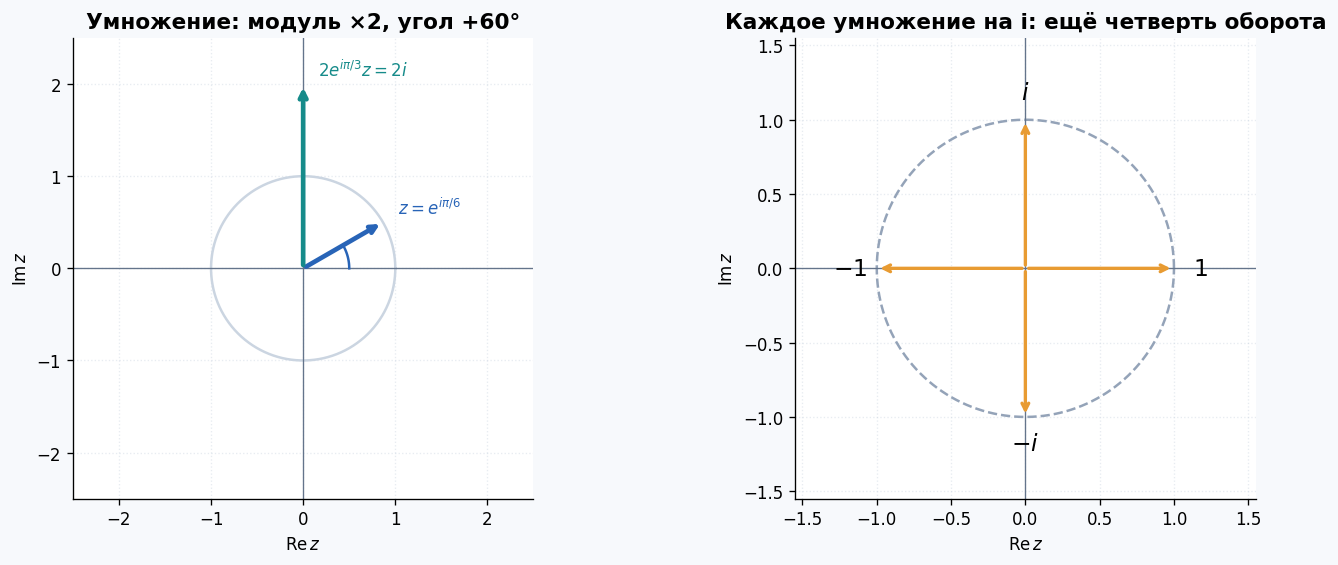

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
t = np.linspace(0, 2*np.pi, 500)
axes[0].plot(np.cos(t), np.sin(t), color='#cbd5e1')
z = np.exp(1j*np.pi/6)
multiplier = 2*np.exp(1j*np.pi/3)
for value, label, color in [(z, r'$z=e^{i\pi/6}$', BLUE), (z*multiplier, r'$2e^{i\pi/3}z=2i$', TEAL)]:
    axes[0].annotate('', (value.real, value.imag), (0,0), arrowprops=dict(arrowstyle='->', color=color, lw=2.8))
    axes[0].annotate(label, (value.real, value.imag), xytext=(9, 5), textcoords='offset points', color=color)
plane(axes[0], 'Умножение: модуль ×2, угол +60°', (-2.5, 2.5))
angle = np.linspace(0, np.pi/6, 80)
axes[0].plot(.5*np.cos(angle), .5*np.sin(angle), color=BLUE)
values = np.exp(1j*np.pi/2 * np.arange(4))
axes[1].plot(np.cos(t), np.sin(t), '--', color='#94a3b8')
for value, label in zip(values, ['$1$', '$i$', '$-1$', '$-i$']):
    axes[1].annotate('', (value.real,value.imag),(0,0),arrowprops=dict(arrowstyle='->',color=ORANGE,lw=2))
    axes[1].text(1.18*value.real,1.18*value.imag,label,ha='center',va='center',fontsize=14)
plane(axes[1], 'Каждое умножение на i: ещё четверть оборота', (-1.55, 1.55))
finish(fig, 'theory_02_rotation')


## 3. Все корни комплексного числа

Пусть нужно решить $z^n=w$, где $w=\rho e^{i\theta}\ne0$. Для $z=re^{i\varphi}$ должны одновременно выполняться
$$r^n=\rho,\qquad n\varphi=\theta+2\pi k.$$
Следовательно,
$$\boxed{z_k=\rho^{1/n}\exp\left(i\frac{\theta+2\pi k}{n}\right),\quad k=0,\ldots,n-1.}$$
Ровно $n$ различных корней лежат на одной окружности, угловой шаг равен $2\pi/n$. Это вершины правильного $n$-угольника. Если $w=0$, корень один, $z=0$, кратности $n$.

**Пример:** $z^3=-8=8e^{i\pi}$. Радиус $2$, углы $\pi/3,\pi,5\pi/3$. Корни: $1+i\sqrt3$, $-2$, $1-i\sqrt3$.

> В этом листке запись $\sqrt[n]{w}$ над полем $\mathbb C$ означает **все** корни. Выражение `w**(1/n)` обычно возвращает лишь одно значение. Поэтому в решениях используем функцию `all_roots`.


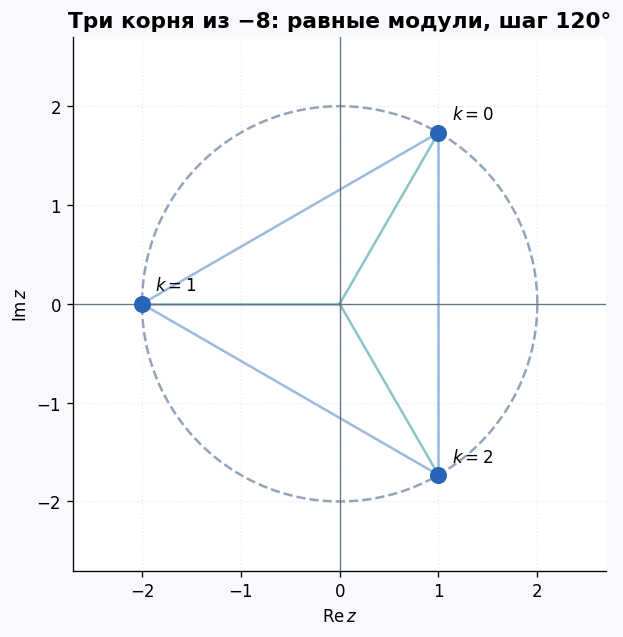

In [4]:
fig, ax = plt.subplots(figsize=(6.3, 5.2), layout='constrained')
roots_demo = all_roots(-8+0j, 3)
circle = 2*np.exp(1j*np.linspace(0,2*np.pi,500))
ax.plot(circle.real,circle.imag,'--',color='#94a3b8')
polygon = np.r_[roots_demo, roots_demo[0]]
ax.plot(polygon.real,polygon.imag,color=BLUE,alpha=.45)
for k, value in enumerate(roots_demo):
    ax.plot([0,value.real],[0,value.imag],color=TEAL,alpha=.5)
    ax.scatter(value.real,value.imag,s=85,color=BLUE,zorder=3)
    ax.annotate(f'$k={k}$', (value.real,value.imag),xytext=(8,8),textcoords='offset points')
plane(ax,r'Три корня из −8: равные модули, шаг 120°',(-2.7,2.7))
finish(fig, 'theory_03_roots')


## 4. Как переводить геометрические условия в координаты

Обычно достаточно подставить $z=x+iy$ и убрать комплексное деление:

| Условие | Что рисуем |
|:--|:--|
| $\vert z-a\vert =R$ | окружность с центром $a$ |
| $\vert z-a\vert <R$ | открытый круг; граница исключена |
| $\vert z-a\vert +\vert z-b\vert <2a_0$ | внутренность эллипса с фокусами $a,b$ |
| $\operatorname{Re}(cz)<d$ | открытую полуплоскость |
| $\vert z-a\vert =\vert z-b\vert $ | серединный перпендикуляр |
| $\alpha\le\operatorname{Arg}w\le\beta$ | сектор в плоскости $w$ |

Если $w=(az+b)/(cz+d)$ и $ad-bc\ne0$, это **дробно-линейное преобразование**. Прямые и окружности переходят в прямые или окружности; границы углового сектора в новой плоскости превращаются в дуги или прямые в исходной. Но сектору соответствует только **нужная сторона** каждой границы.

Практический способ: вычислить $u=\operatorname{Re}w$ и $v=\operatorname{Im}w$, затем записать сектор через неравенства для $u,v$. Например, $0<\operatorname{Arg}w<\pi/2$ эквивалентно $u>0,v>0$. Нужно отдельно исключить нули знаменателя и точки $w=0$.

Для суммы квадратов полезно выделять полный квадрат:
$$A|z|^2+\bar Bz+B\bar z+C
=A\left|z+\frac BA\right|^2+C-\frac{|B|^2}{A}.$$


## 5. Многочлен, его корни и проверка численного ответа

Основная теорема алгебры: многочлен степени $n$ имеет $n$ комплексных корней **с учётом кратностей**. Для действительных коэффициентов недействительные корни идут сопряжёнными парами.

В высоких степенях удобно искать корни численно. `numpy.roots` даёт приближения; `sympy.nroots` позволяет увеличить точность. Но количество выведенных знаков само по себе ничего не доказывает. Полезны независимые проверки:

1. **Невязка:** $|p(z_k)|$ должна быть мала. Для крупных коэффициентов полезна относительная невязка $|p(z_k)|/\sum_j|a_j||z_k|^{n-j}$.
2. **Формулы Виета:** $\sum z_k=-a_{n-1}/a_n$, $\prod z_k=(-1)^n a_0/a_n$.
3. **Сопряжённость:** у недействительного корня должен быть партнёр с противоположной мнимой частью.

Сумма модулей $\sum|z_k|$ отличается от модуля суммы $|\sum z_k|$. Подмена одного другим — частая ошибка.

## 6. Гамма-функция и обобщённые сочетания

Для натуральных $n$ число $n!=1\cdot2\cdots n$ связано с функцией
$$\Gamma(z)=\int_0^\infty t^{z-1}e^{-t}\,dt,\quad\operatorname{Re}z>0,
\qquad \Gamma(n+1)=n!.$$
С помощью $\Gamma(z+1)=z\Gamma(z)$ функцию продолжают за пределы этой полуплоскости. В точках $0,-1,-2,\ldots$ у неё полюса. Поэтому формула
$$C_z^w=\frac{\Gamma(z+1)}{\Gamma(w+1)\Gamma(z-w+1)}$$
задаёт комплексное обобщение биномиальных коэффициентов там, где выражение корректно; отдельные особенности могут требовать предельного перехода. Обычно результат — уже не целое число способов что-либо выбрать.

Для огромных значений вместо трёх гамма-функций вычисляют
$$L=\log\Gamma(z+1)-\log\Gamma(w+1)-\log\Gamma(z-w+1),\qquad C_z^w=e^L.$$
Модуль равен $e^{\operatorname{Re}L}$, а для фазы достаточно
$$\operatorname{Arg}C_z^w=\operatorname{atan2}(\sin\operatorname{Im}L,\cos\operatorname{Im}L).$$
Это не требует вычисления огромного $e^{\operatorname{Re}L}$. В графике фазы используется циклическая шкала: $-\pi$ и $\pi$ обозначают одно направление. В нулях и полюсах фазу не рисуем. Сведения о продолжении и полюсах: [NIST DLMF, §5.2](https://dlmf.nist.gov/5.2).


## 7. Итерации и множества Жюлиа

Берём начальное число $z_0$ и многократно применяем одну функцию:
$$z_0\mapsto z_1=f(z_0)\mapsto z_2=f(f(z_0))\mapsto\cdots.$$
Эта последовательность называется **орбитой**. Для $f_c(z)=z^2+c$ некоторые орбиты остаются ограниченными, другие уходят к бесконечности. Множество ограниченных орбит — **заполненное множество Жюлиа** $K_c$, а его граница $J_c=\partial K_c$ — собственно множество Жюлиа.

### Полиномиальный случай: время ухода

Для двух заданных $c$ выполнено $|c|<2$. Если $|z|>2$, то
$$|z^2+c|\ge |z|^2-|c|>|z|$$
и дальнейшая орбита уходит к бесконечности. Поэтому можно считать итерации до первого выхода за радиус $2$. Цвет показывает **время ухода**, тёмный цвет — отсутствие ухода за выбранное число шагов. Это конечная численная аппроксимация $K_c$ и его границы, а не доказательство принадлежности отдельной точки.

### Рациональный случай: обратные итерации

Для отношения многочленов большой модуль не означает ухода: следующая итерация может снова стать маленькой, а полюс отображается в точку $\infty$ на сфере. Поэтому один и тот же критерий $|z|>2$ здесь неприменим.

Используем обратные итерации: для текущего $w$ решаем $f(z)=w$, равновероятно выбираем один из прообразов и повторяем. После переходного участка получаем облако точек, приближающее множество Жюлиа. Исключительные начальные точки нужно избегать; в коде используются многие случайные старты и фиксированный `seed`. Метод и его обоснование описаны у [Stankewitz и Sumi](https://arxiv.org/abs/1312.1457). Конечное облако не обязано равномерно заполнять все видимые детали: плотность отражает меру обратных итераций.

**Отличие от множества Мандельброта:** здесь $c$ фиксировано, а меняется стартовая точка $z_0$. Для множества Мандельброта меняется параметр $c$, а стартуют из $z_0=0$.


## 8. Сфера Римана: где находится бесконечность

К комплексной плоскости добавляют одну точку $\infty$ и отождествляют полученную поверхность со сферой. Возьмём **единичную сферу с центром в начале координат**. Если $z=x+iy$, то обратная стереографическая проекция имеет вид
$$\boxed{X=\frac{2x}{1+x^2+y^2},\quad
Y=\frac{2y}{1+x^2+y^2},\quad
Z=\frac{x^2+y^2-1}{1+x^2+y^2}.}$$
Подстановка даёт $X^2+Y^2+Z^2=1$. Ноль переходит в южный полюс $(0,0,-1)$, единичная окружность — в экватор, а $|z|\to\infty$ соответствует северному полюсу $N=(0,0,1)$. Обратная формула: $z=(X+iY)/(1-Z)$ при $Z\ne1$.

Геометрическое построение: проводим прямую от $N$ к точке $(x,y,0)$ плоскости и берём второе пересечение со сферой. Прямая на плоскости после добавления бесконечности становится окружностью через $N$. Обычная окружность становится окружностью на сфере, не проходящей через $N$. Параболы, гиперболы и спирали проектируются по тем же координатным формулам.

В PDF иллюстрации используют также сферу, касающуюся плоскости. Это другое размещение в пространстве; смысл стереографической проекции тот же. Здесь во всех рисунках соблюдается одна, указанная выше нормировка.


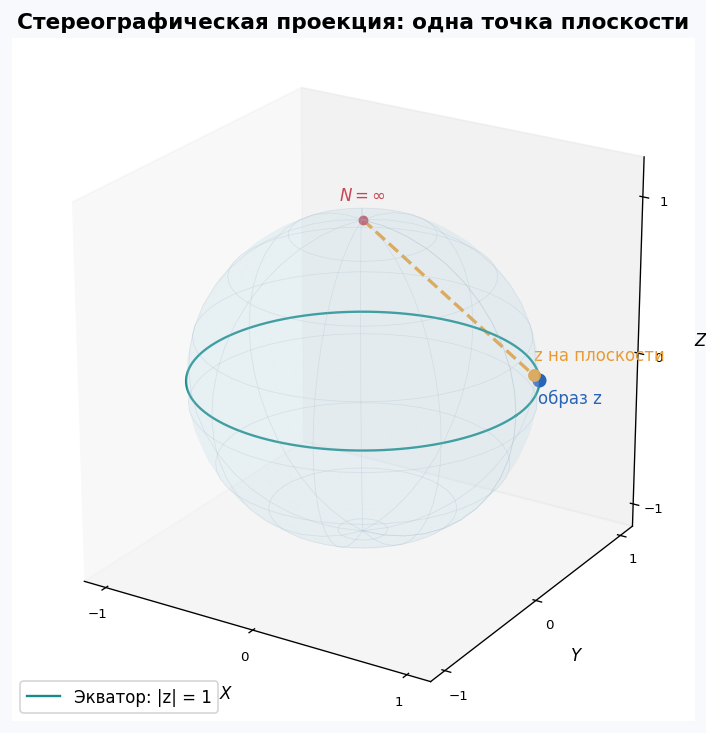

In [5]:
def stereo(z):
    z = np.asarray(z, dtype=complex)
    r2 = np.abs(z)**2
    den = 1+r2
    return 2*z.real/den, 2*z.imag/den, (r2-1)/den

def sphere(ax, title=''):
    u, v = np.meshgrid(np.linspace(0,2*np.pi,45), np.linspace(0,np.pi,23))
    ax.plot_surface(np.sin(v)*np.cos(u), np.sin(v)*np.sin(u), np.cos(v),
                    color='#bddce9', alpha=.14, edgecolor='none', shade=False)
    ax.plot_wireframe(np.sin(v)*np.cos(u), np.sin(v)*np.sin(u), np.cos(v),
                      rstride=3, cstride=5, color='#9aaebd', alpha=.25, linewidth=.5)
    ax.scatter([0],[0],[1],s=24,color=RED)
    ax.text(0,0,1.12,r'$N=\infty$',color=RED,ha='center',fontsize=10)
    ax.set(xlim=(-1.15,1.15),ylim=(-1.15,1.15),zlim=(-1.15,1.25),
           xlabel='$X$',ylabel='$Y$',zlabel='$Z$',title=title)
    ax.set_box_aspect((1,1,1))
    ax.set_xticks([-1,0,1]);ax.set_yticks([-1,0,1]);ax.set_zticks([-1,0,1])
    ax.tick_params(labelsize=8,pad=0)
    ax.view_init(elev=23,azim=-58)
    ax.grid(False)

fig = plt.figure(figsize=(8,6),layout='constrained')
ax = fig.add_subplot(111,projection='3d')
sphere(ax,'Стереографическая проекция: одна точка плоскости')
z_demo = .8+.55j
p = np.array(stereo(z_demo))
ax.plot([0,z_demo.real],[0,z_demo.imag],[1,0],'--',color=ORANGE,lw=2)
ax.scatter([z_demo.real],[z_demo.imag],[0],s=45,color=ORANGE)
ax.scatter([p[0]],[p[1]],[p[2]],s=55,color=BLUE)
ax.text(z_demo.real,z_demo.imag,0.1,'z на плоскости',color=ORANGE)
ax.text(p[0],p[1],p[2]-.15,'образ z',color=BLUE)
t=np.linspace(0,2*np.pi,400)
ax.plot(np.cos(t),np.sin(t),0*t,color=TEAL,lw=1.4,label='Экватор: |z| = 1')
ax.legend(loc='lower left')
finish(fig, 'theory_04_riemann')


# Часть II. Решения всех задач

<a id="task21"></a>
## 2.1. Алгебраическая, тригонометрическая и показательная формы

### a) $\displaystyle\frac{(5+i)(7-6i)}{3+i}$

Числитель равен $35-30i+7i-6i^2=41-23i$. Домножаем на $3-i$:
$$\frac{(41-23i)(3-i)}{(3+i)(3-i)}=\frac{100-110i}{10}=10-11i.$$
Модуль $r=\sqrt{221}$, главный аргумент $\varphi=-\arctan(11/10)$: точка в IV четверти.

### b) $\displaystyle\frac{(1+i)^5}{(1-i)^3}$

Используем $1+i=\sqrt2e^{i\pi/4}$ и $1-i=\sqrt2e^{-i\pi/4}$:
$$\frac{(\sqrt2)^5e^{5\pi i/4}}{(\sqrt2)^3e^{-3\pi i/4}}
=2e^{2\pi i}=2.$$

### c) $\displaystyle\frac{(-1+i\sqrt3)^{15}}{(1-i)^{20}}+\frac{(-1-i\sqrt3)^{15}}{(1+i)^{20}}$

Здесь $-1\pm i\sqrt3=2e^{\pm2\pi i/3}$. Каждый числитель равен $2^{15}e^{\pm10\pi i}=2^{15}$, а каждый знаменатель — $2^{10}e^{\mp5\pi i}=-2^{10}$. Получаем $-32-32=-64$.

| Пункт | Алгебраическая форма | Тригонометрическая форма | Показательная форма |
|:--|:--|:--|:--|
| a | $10-11i$ | $\sqrt{221}(\cos\varphi+i\sin\varphi)$, $\varphi=-\arctan(11/10)$ | $\sqrt{221}e^{-i\arctan(11/10)}$ |
| b | $2+0i$ | $2(\cos0+i\sin0)$ | $2e^{0i}$ |
| c | $-64+0i$ | $64(\cos\pi+i\sin\pi)$ | $64e^{i\pi}$ |

На рисунке слева — сами ответы; справа — их направления на единичной окружности, чтобы разница модулей не скрывала углы.


a: z = 10.000000 -11.000000i, |z| = 14.86606875, Arg z = -0.83298127 рад (-47.726°)
b: z = 2.000000 +0.000000i, |z| = 2.00000000, Arg z = 0.00000000 рад (0.000°)
c: z = -64.000000 +0.000000i, |z| = 64.00000000, Arg z = 3.14159265 рад (180.000°)


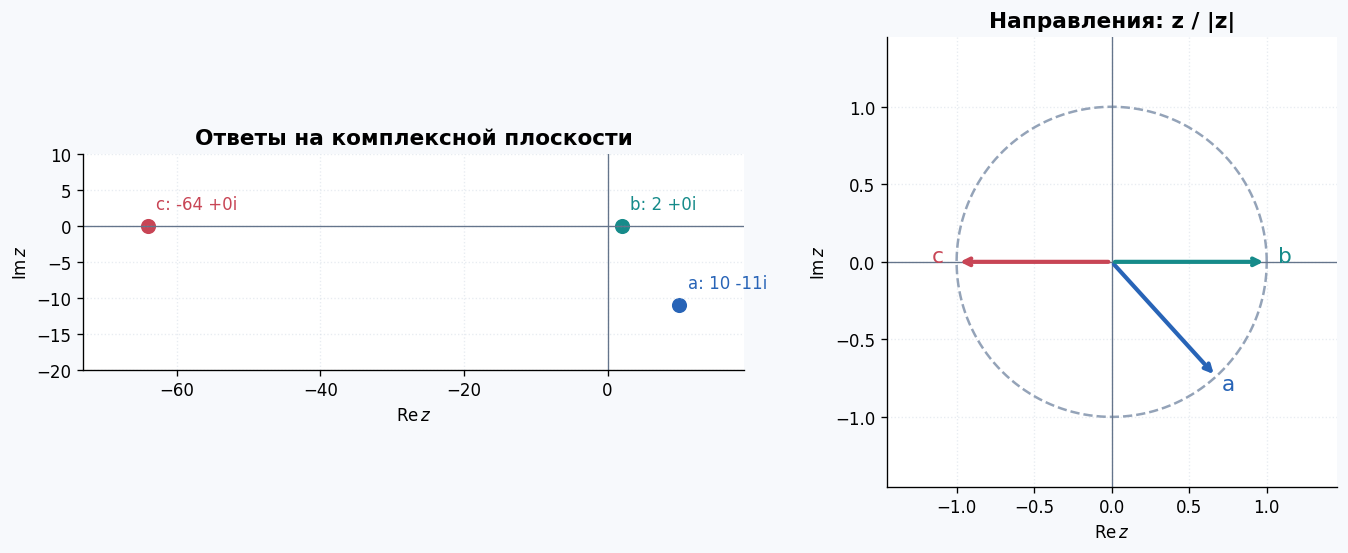

In [6]:
i = sp.I
expr21 = [((5+i)*(7-6*i))/(3+i), (1+i)**5/(1-i)**3,
          (-1+i*sp.sqrt(3))**15/(1-i)**20+(-1-i*sp.sqrt(3))**15/(1+i)**20]
exact21 = [sp.simplify(sp.expand_complex(v)) for v in expr21]
assert exact21 == [10-11*i, sp.Integer(2), sp.Integer(-64)]
values21 = np.array([complex(v) for v in exact21])
for label,z in zip('abc',values21):
    phi = np.pi if z.real < 0 and abs(z.imag) < 1e-12 else np.angle(z)
    print(f'{label}: z = {fmt(z)}, |z| = {abs(z):.8f}, Arg z = {phi:.8f} рад ({np.degrees(phi):.3f}°)')
fig, axes = plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for label,z,color in zip('abc',values21,[BLUE,TEAL,RED]):
    axes[0].scatter(z.real,z.imag,color=color,s=65)
    axes[0].annotate(f'{label}: {fmt(z,0)}',(z.real,z.imag),xytext=(5,10),textcoords='offset points',color=color)
    unit = z/abs(z)
    axes[1].annotate('',(unit.real,unit.imag),(0,0),arrowprops=dict(arrowstyle='->',color=color,lw=2.5))
    axes[1].text(1.12*unit.real,1.12*unit.imag,label,color=color,ha='center',fontsize=13)
plane(axes[0],'Ответы на комплексной плоскости')
axes[0].set_xlim(-73,19);axes[0].set_ylim(-20,10)
t = np.linspace(0,2*np.pi,500)
axes[1].plot(np.cos(t),np.sin(t),'--',color='#94a3b8')
plane(axes[1],'Направления: z / |z|',(-1.45,1.45))
finish(fig,'task_2_1_forms')


<a id="task22"></a>
## 2.2. Решить $z^8=1+i$

Представим правую часть как $1+i=\sqrt2e^{i\pi/4}$. Восьмой корень из модуля равен $(\sqrt2)^{1/8}=2^{1/16}$, а угол делим на восемь, учитывая все обороты:
$$\boxed{z_k=2^{1/16}e^{i(\pi/32+\pi k/4)},\quad k=0,\ldots,7.}$$
Решения — вершины правильного восьмиугольника радиуса $2^{1/16}\approx1.044274$. Первый луч образует угол $\pi/32=5.625^\circ$, угловой шаг равен $45^\circ$. Ниже каждый корень проверяется подстановкой в восьмую степень.


k=0: 1.03924532 +0.10235673i
k=1: 0.66248027 +0.80723455i
k=2: -0.10235673 +1.03924532i
k=3: -0.80723455 +0.66248027i
k=4: -1.03924532 -0.10235673i
k=5: -0.66248027 -0.80723455i
k=6: 0.10235673 -1.03924532i
k=7: 0.80723455 -0.66248027i
Максимальная невязка: 6.92e-15


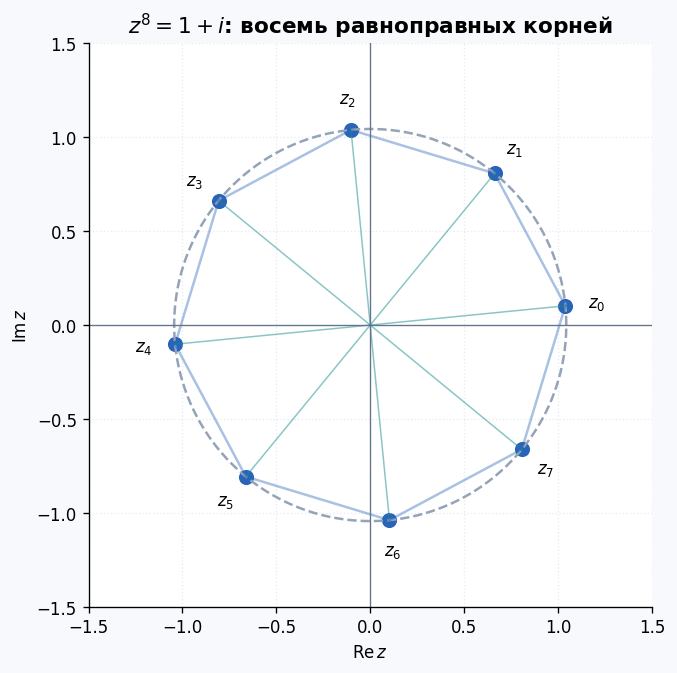

In [7]:
r22 = all_roots(1+1j,8)
for k,z in enumerate(r22):
    print(f'k={k}: {fmt(z,8)}')
assert np.allclose(r22**8,1+1j,atol=1e-12)
print('Максимальная невязка:',f'{np.max(abs(r22**8-(1+1j))):.2e}')
fig,ax=plt.subplots(figsize=(6.6,5.5),layout='constrained')
t=np.linspace(0,2*np.pi,500); circle=2**(1/16)*np.exp(1j*t)
ax.plot(circle.real,circle.imag,'--',color='#94a3b8')
polygon=np.r_[r22,r22[0]]
ax.plot(polygon.real,polygon.imag,color=BLUE,alpha=.4)
for k,z in enumerate(r22):
    ax.plot([0,z.real],[0,z.imag],color=TEAL,lw=.9,alpha=.5)
    ax.scatter(z.real,z.imag,s=65,color=BLUE)
    ax.text(1.16*z.real,1.16*z.imag,f'$z_{k}$',ha='center',va='center')
plane(ax,r'$z^8=1+i$: восемь равноправных корней',(-1.5,1.5))
finish(fig,'task_2_2_roots')


<a id="task23"></a>
## 2.3. Вычислить все корни и изобразить их

### a) $\sqrt[8]{1}$

$1=e^{2\pi im}$, поэтому
$$\boxed{z_k=e^{i\pi k/4},\quad k=0,\ldots,7.}$$
Это $1,(1+i)/\sqrt2,i,(-1+i)/\sqrt2,-1,(-1-i)/\sqrt2,-i,(1-i)/\sqrt2$.

### b) $\displaystyle\sqrt[4]{-\frac{18}{1+i\sqrt3}}$

Домножим дробь на сопряжённое:
$$-\frac{18}{1+i\sqrt3}=-\frac92+\frac{9\sqrt3}{2}i=9e^{2\pi i/3}.$$
Следовательно,
$$\boxed{z_k=\sqrt3e^{i(\pi/6+\pi k/2)},\quad k=0,1,2,3.}$$
В алгебраической форме это $3/2+i\sqrt3/2$, $-\sqrt3/2+3i/2$, $-3/2-i\sqrt3/2$, $\sqrt3/2-3i/2$.

### c) $\displaystyle\sqrt[3]{\frac{1-5i}{1+i}-5\frac{1+2i}{2-i}+11}$

Весь указанный результат находится **под кубическим корнем**. Сначала упрощаем:
$$\frac{1-5i}{1+i}=-2-3i,\qquad\frac{1+2i}{2-i}=i,$$
$$(-2-3i)-5i+11=9-8i=\sqrt{145}e^{-i\arctan(8/9)}.$$
Значит,
$$\boxed{z_k=145^{1/6}\exp\left(i\frac{-\arctan(8/9)+2\pi k}{3}\right),\quad k=0,1,2.}$$

### d) $\sqrt[9]{1-i}$

$1-i=\sqrt2e^{-i\pi/4}$, поэтому
$$\boxed{z_k=2^{1/18}e^{i(-\pi/36+2\pi k/9)},\quad k=0,\ldots,8.}$$
Радиус $2^{1/18}$, начальный угол $-5^\circ$, угловой шаг $40^\circ$.



a: степень 8, подкоренное число 1.000000 +0.000000i, радиус 1.00000000
  k=0: 1.0000000 +0.0000000i
  k=1: 0.7071068 +0.7071068i
  k=2: 0.0000000 +1.0000000i
  k=3: -0.7071068 +0.7071068i
  k=4: -1.0000000 +0.0000000i
  k=5: -0.7071068 -0.7071068i
  k=6: -0.0000000 -1.0000000i
  k=7: 0.7071068 -0.7071068i

b: степень 4, подкоренное число -4.500000 +7.794229i, радиус 1.73205081
  k=0: 1.5000000 +0.8660254i
  k=1: -0.8660254 +1.5000000i
  k=2: -1.5000000 -0.8660254i
  k=3: 0.8660254 -1.5000000i

c: степень 3, подкоренное число 9.000000 -8.000000i, радиус 2.29207065
  k=0: 2.2251635 -0.5497593i
  k=1: -0.6364762 +2.2019278i
  k=2: -1.5886873 -1.6521684i

d: степень 9, подкоренное число 1.000000 -1.000000i, радиус 1.03925923
  k=0: 1.0353045 -0.0905774i
  k=1: 0.8513113 +0.5960946i
  k=2: 0.2689801 +1.0038473i
  k=3: -0.4392099 +0.9418887i
  k=4: -0.9418887 +0.4392099i
  k=5: -1.0038473 -0.2689801i
  k=6: -0.5960946 -0.8513113i
  k=7: 0.0905774 -1.0353045i
  k=8: 0.7348672 -0.7348672i


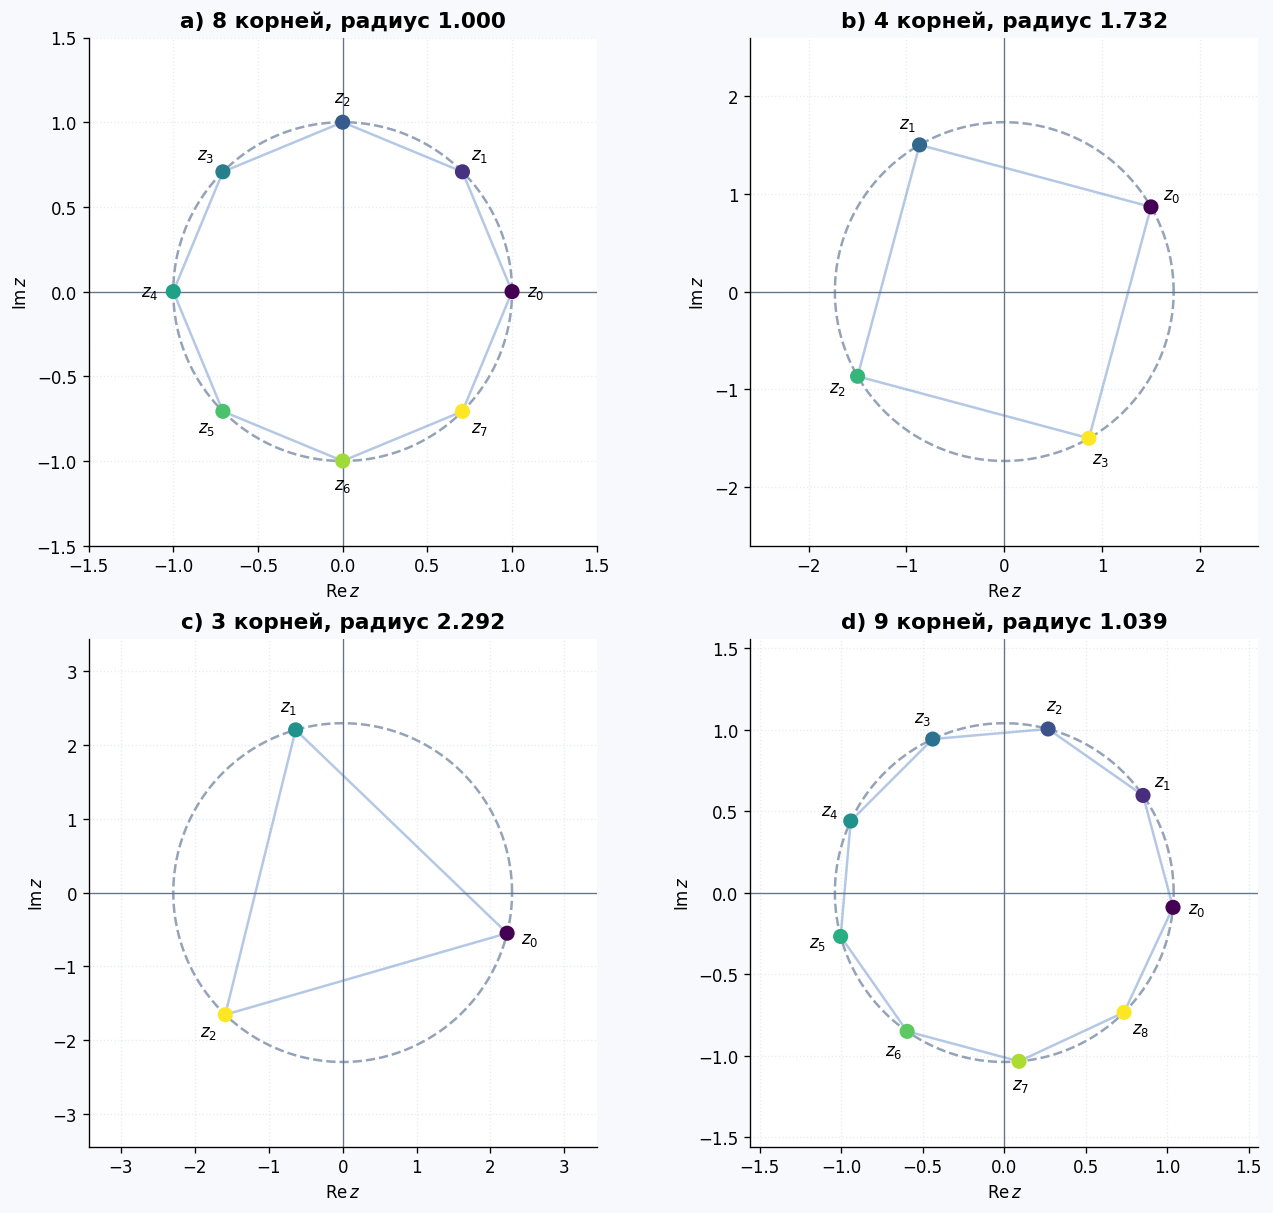

In [8]:
radicand_b = complex(sp.simplify(-18/(1+sp.I*sp.sqrt(3))))
radicand_c = complex(sp.simplify((1-5*sp.I)/(1+sp.I)-5*(1+2*sp.I)/(2-sp.I)+11))
assert np.isclose(radicand_c,9-8j)
root_cases = [('a',1+0j,8),('b',radicand_b,4),('c',radicand_c,3),('d',1-1j,9)]
fig,axes=plt.subplots(2,2,figsize=(11,10),layout='constrained')
for ax,(label,w,n) in zip(axes.flat,root_cases):
    rr=all_roots(w,n); radius=abs(w)**(1/n)
    print(f'\n{label}: степень {n}, подкоренное число {fmt(w)}, радиус {radius:.8f}')
    for k,z in enumerate(rr): print(f'  k={k}: {fmt(z,7)}')
    assert np.allclose(rr**n,w,atol=1e-11)
    t=np.linspace(0,2*np.pi,500)
    ax.plot(radius*np.cos(t),radius*np.sin(t),'--',color='#94a3b8')
    pp=np.r_[rr,rr[0]];ax.plot(pp.real,pp.imag,color=BLUE,alpha=.35)
    ax.scatter(rr.real,rr.imag,c=np.arange(n),cmap='viridis',s=65,zorder=4)
    for k,z in enumerate(rr):
        ax.text(1.14*z.real,1.14*z.imag,f'$z_{k}$',ha='center',va='center')
    plane(ax,f'{label}) {n} корней, радиус {radius:.3f}',(-1.5*radius,1.5*radius))
finish(fig,'task_2_3_all_roots')


<a id="task24"></a>
## 2.4. Геометрические множества

### a) $|z-i|+|z+i|<4$

Фокусы $i$ и $-i$ лежат на вертикальной оси. Сумма расстояний меньше $2a=4$, так что $a=2$, фокусное расстояние от центра $c=1$, а малая полуось $b=\sqrt{a^2-c^2}=\sqrt3$.
$$\boxed{\frac{x^2}{3}+\frac{y^2}{4}<1.}$$
Это внутренность эллипса с вертикальной большой осью. Граница исключена.

### b) $\operatorname{Re}(z(1-i))<\sqrt2$

$$z(1-i)=(x+y)+i(y-x),\qquad\boxed{x+y<\sqrt2.}$$
Получаем открытую полуплоскость ниже прямой $y=\sqrt2-x$. Начало координат входит в ответ.

### c) $|z+1|=|z+i|=|z-i|$

Из $x^2+(y+1)^2=x^2+(y-1)^2$ следует $y=0$. Тогда $(x+1)^2=x^2+1$, откуда $x=0$.
$$\boxed{z=0.}$$
Проверка: расстояния от нуля до $-1,-i,i$ равны единице.

### d) $\displaystyle 0<\operatorname{Arg}\frac{i-z}{z+i}<\frac\pi2$

После домножения на сопряжённый знаменатель:
$$\frac{i-z}{z+i}=\frac{1-x^2-y^2+2ix}{x^2+(y+1)^2}.$$
При $z\ne-i$ знаменатель положителен. Требуем положительности обеих частей:
$$\boxed{x>0,\qquad x^2+y^2<1.}$$
Ответ — открытая правая половина единичного круга. Диаметр и полуокружность исключены; точки $i$ (нулевой числитель) и $-i$ (нулевой знаменатель) уже лежат на исключённой границе.

### e) $\displaystyle-\frac{2\pi}{3}\le\operatorname{Arg}\frac{2-iz}{z+3i}\le-\frac{5\pi}{6}$

Левая граница $-120^\circ$ **больше** правой $-150^\circ$. Ни одно действительное число не может одновременно быть не меньше $-120^\circ$ и не больше $-150^\circ$.
$$\boxed{\varnothing.}$$
В исходнике, вероятно, опечатка, но буквальное условие имеет именно такой ответ. Перестановка границ означала бы другую задачу. Даже многозначность аргумента не делает этот числовой интервал непустым.

### f) $\displaystyle-\frac{2\pi}{3}\le\operatorname{Arg}\frac{3-z}{z+i}\le-\frac\pi3$

Обозначим
$$D=x^2+(y+1)^2,\quad U=3x-x^2-y^2-y,\quad V=x-3y-3.$$
Тогда $w=(3-z)/(z+i)=(U+iV)/D$. Нужный сектор направлен вниз, с отклонением от отрицательной мнимой полуоси не более $30^\circ$. Поэтому $v<0$ и $|u|\le-v/\sqrt3$. После умножения на $D>0$:
$$\boxed{V<0,\qquad \sqrt3|U|\le -V,\qquad z\ne-i.}$$
Это точное координатное описание области между двумя дугами окружностей $V\pm\sqrt3U=0$. Граничные дуги **включены**, а их общие концы **исключены**: $z=3$ даёт $w=0$ без аргумента, $z=-i$ обращает знаменатель в ноль. Условие $V<0$ исключает $z=3$ автоматически. Проверочная внутренняя точка: $z=i$ даёт $w=-1/2-3i/2$, угол около $-108.435^\circ$.

На графиках цветом показаны решения; пунктир означает исключённую границу, сплошная линия — включённую, незакрашенные точки — исключённые концы. Рисунок f показывает только соответствующие сектору дуги, а не целые окружности.


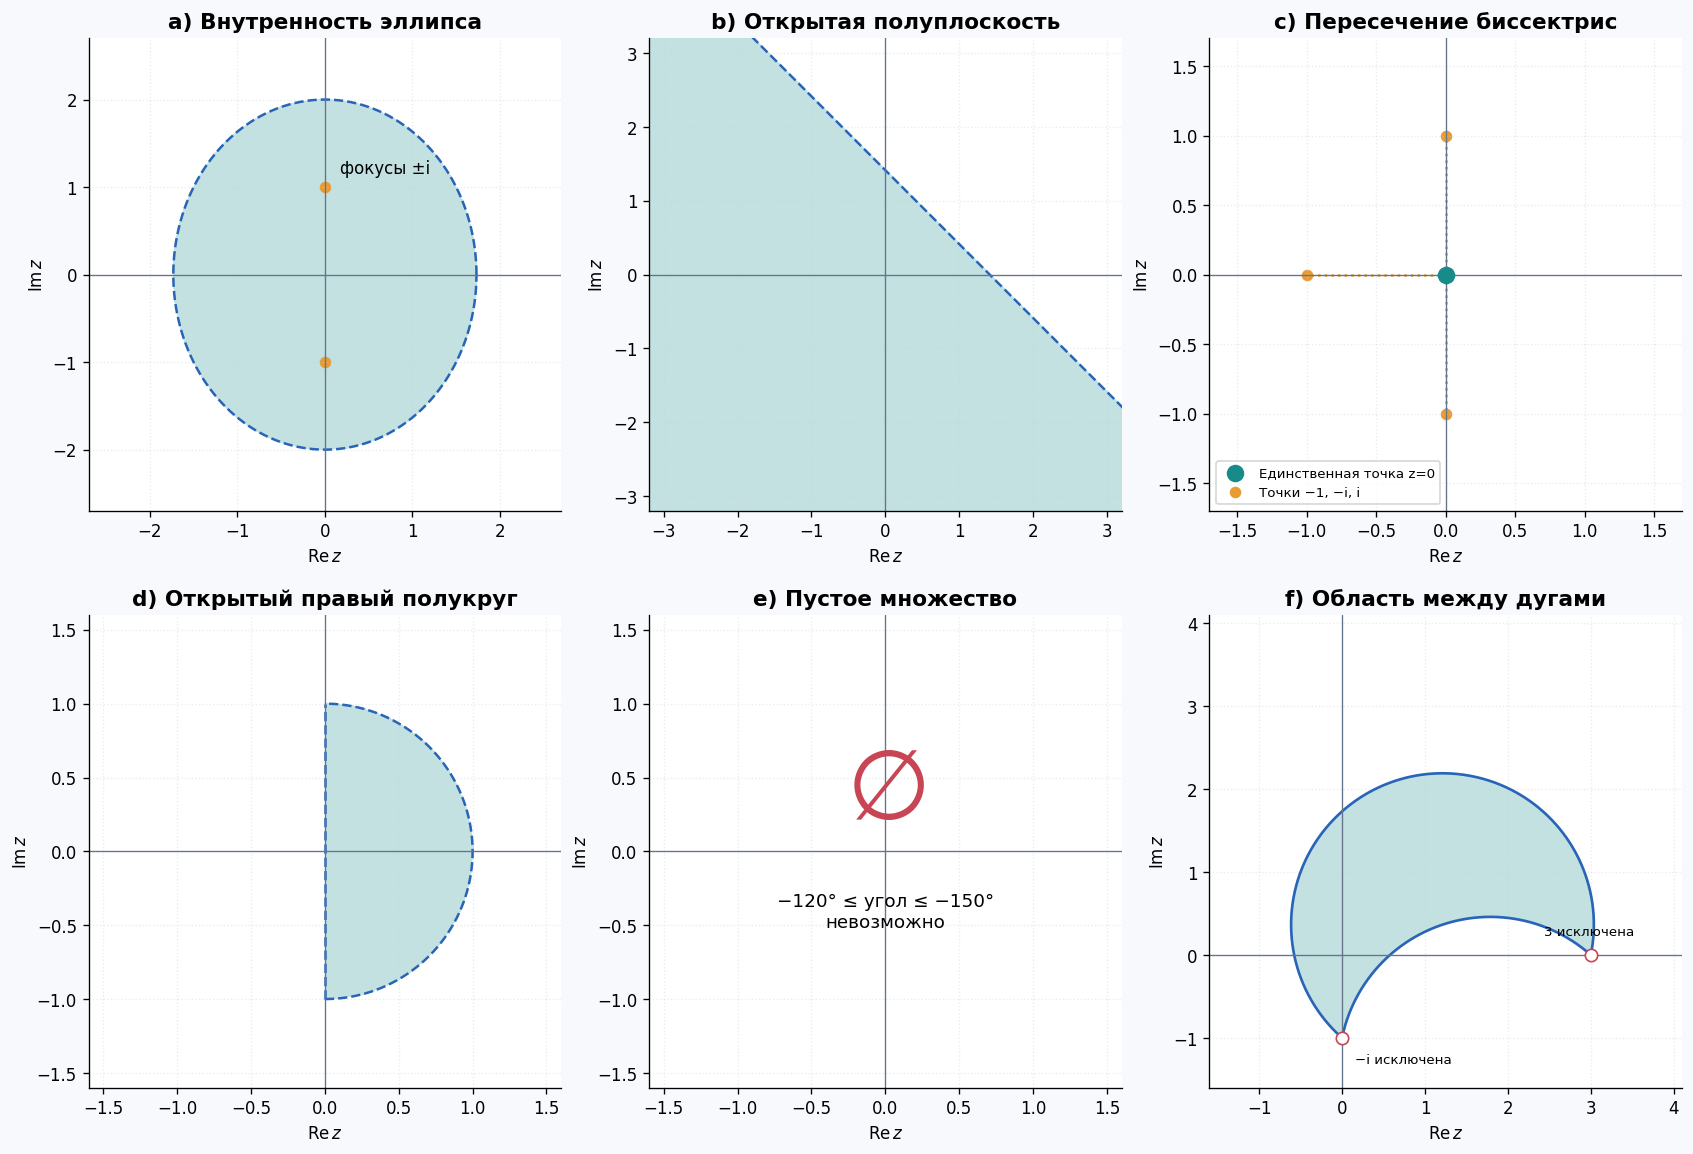

Сверка d и f по 20 000 случайных точек: формулы совпали с исходными неравенствами.


In [9]:
grid = np.linspace(-4.2,4.2,901)
X,Y=np.meshgrid(grid,grid); Z=X+1j*Y
U=3*X-X**2-Y**2-Y;V=X-3*Y-3;D=X**2+(Y+1)**2
mask_f=(V<0)&(np.sqrt(3)*abs(U)<=-V)&(D>1e-14)

# Независимая сверка координатного описания с исходными аргументами.
rng=np.random.default_rng(2026)
testz=rng.uniform(-4,4,20000)+1j*rng.uniform(-4,4,20000)
wd=(1j-testz)/(testz+1j)
assert np.array_equal((np.angle(wd)>0)&(np.angle(wd)<np.pi/2),
                      (testz.real>0)&(abs(testz)<1))
wf=(3-testz)/(testz+1j)
ut=3*testz.real-abs(testz)**2-testz.imag
vt=testz.real-3*testz.imag-3
assert np.array_equal((np.angle(wf)>=-2*np.pi/3)&(np.angle(wf)<=-np.pi/3),
                      (vt<0)&(np.sqrt(3)*abs(ut)<=-vt))

fig,axes=plt.subplots(2,3,figsize=(14,9.6),layout='constrained')
def shade(ax,mask):
    ax.contourf(X,Y,mask.astype(float),levels=[.5,1.5],colors=[TEAL],alpha=.26)
t=np.linspace(0,2*np.pi,500)
shade(axes[0,0],X**2/3+Y**2/4<1)
axes[0,0].plot(np.sqrt(3)*np.cos(t),2*np.sin(t),'--',color=BLUE)
axes[0,0].scatter([0,0],[1,-1],c=ORANGE,s=35)
axes[0,0].annotate('фокусы ±i',(0,1),xytext=(9,8),textcoords='offset points')
shade(axes[0,1],X+Y<np.sqrt(2))
axes[0,1].plot(grid,np.sqrt(2)-grid,'--',color=BLUE)
axes[0,2].scatter([0],[0],s=90,color=TEAL,zorder=5,label='Единственная точка z=0')
axes[0,2].scatter([-1,0,0],[0,-1,1],s=35,color=ORANGE,label='Точки −1, −i, i')
for a in [-1,-1j,1j]: axes[0,2].plot([0,np.real(a)],[0,np.imag(a)],':',color=ORANGE)
axes[0,2].legend(loc='lower left',fontsize=8)
shade(axes[1,0],(X>0)&(X**2+Y**2<1))
td=np.linspace(-np.pi/2,np.pi/2,400)
axes[1,0].plot(np.cos(td),np.sin(td),'--',color=BLUE)
axes[1,0].plot([0,0],[-1,1],'--',color=BLUE)
axes[1,1].text(.5,.57,r'$\varnothing$',transform=axes[1,1].transAxes,ha='center',fontsize=58,color=RED)
axes[1,1].text(.5,.34,'−120° ≤ угол ≤ −150°\nневозможно',transform=axes[1,1].transAxes,ha='center',fontsize=11)
shade(axes[1,2],mask_f)
# Прообраз граничного луча w=t·exp(iα): z=(3−iw)/(1+w), t>0.
rho=np.geomspace(1e-5,1e5,2500)
for alpha in [-2*np.pi/3,-np.pi/3]:
    w=rho*np.exp(1j*alpha); curve=(3-1j*w)/(1+w)
    axes[1,2].plot(curve.real,curve.imag,color=BLUE,lw=1.6)
axes[1,2].scatter([3,0],[0,-1],s=55,facecolors='white',edgecolors=RED,zorder=6)
axes[1,2].annotate('3 исключена',(3,0),xytext=(-28,12),textcoords='offset points',fontsize=8)
axes[1,2].annotate('−i исключена',(0,-1),xytext=(8,-15),textcoords='offset points',fontsize=8)
titles=['a) Внутренность эллипса','b) Открытая полуплоскость','c) Пересечение биссектрис',
        'd) Открытый правый полукруг','e) Пустое множество','f) Область между дугами']
limits=[(-2.7,2.7),(-3.2,3.2),(-1.7,1.7),(-1.6,1.6),(-1.6,1.6),(-1.6,4.1)]
for ax,title,lim in zip(axes.flat,titles,limits):plane(ax,title,lim)
finish(fig,'task_2_4_regions')
print('Сверка d и f по 20 000 случайных точек: формулы совпали с исходными неравенствами.')


<a id="task25"></a>
## 2.5*. Общее уравнение окружности

**Дано:** $A,C\in\mathbb R$, $B\in\mathbb C$, $A>0$, $AC<|B|^2$ и
$$A|z|^2+\bar Bz+B\bar z+C=0.$$

Делим на $A$ и выделяем полный квадрат. Обратите внимание на сопряжение: в исходнике коэффициент при $z$ — именно $\bar B$.
$$\begin{aligned}
|z|^2+\frac{\bar B}{A}z+\frac BA\bar z+\frac CA&=0,\\
\left|z+\frac BA\right|^2&=\frac{|B|^2-AC}{A^2}.
\end{aligned}$$
Правая часть положительна по условию. Следовательно, это окружность:
$$\boxed{z_0=-\frac BA,\qquad R=\frac{\sqrt{|B|^2-AC}}{A}.}$$
Если $B=b_1+ib_2$, центр имеет координаты $(-b_1/A,-b_2/A)$. При равенстве $AC=|B|^2$ получилась бы одна точка; при $AC>|B|^2$ — пустое множество. Эти два случая не входят в условие, но объясняют необходимость строгого неравенства.

Ниже для иллюстрации выбраны $A=2$, $B=1+0.5i$, $C=-1$; общая формула доказана выше и не зависит от этого выбора.


Центр: -0.500000 -0.250000i Радиус: 0.901387819


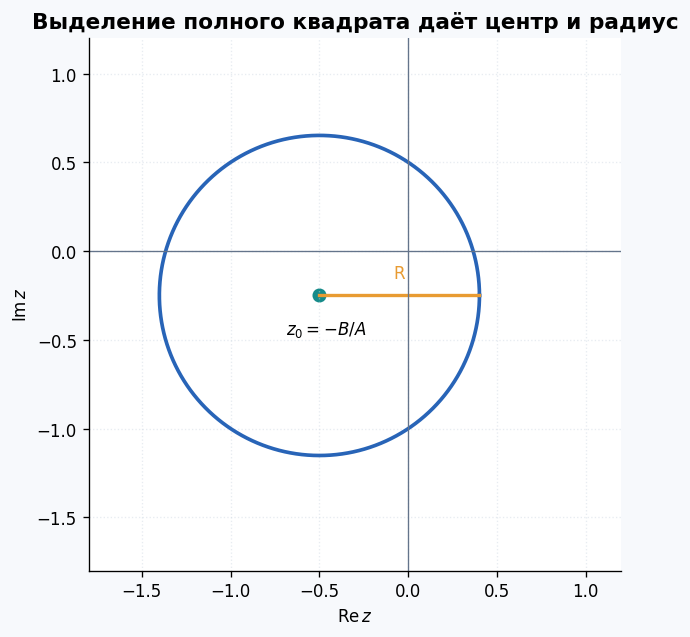

In [10]:
A,B,C=2.,1+.5j,-1.
center=-B/A;radius=np.sqrt(abs(B)**2-A*C)/A
t=np.linspace(0,2*np.pi,700);circle=center+radius*np.exp(1j*t)
residual=A*abs(circle)**2+B.conjugate()*circle+B*circle.conjugate()+C
assert np.max(abs(residual))<1e-12
print('Центр:',fmt(center),'Радиус:',f'{radius:.9f}')
fig,ax=plt.subplots(figsize=(6.4,5.2),layout='constrained')
ax.plot(circle.real,circle.imag,color=BLUE,lw=2.2)
ax.scatter(center.real,center.imag,color=TEAL,s=55)
ax.plot([center.real,center.real+radius],[center.imag,center.imag],color=ORANGE,lw=2)
ax.annotate(r'$z_0=-B/A$',(center.real,center.imag),xytext=(-20,-23),textcoords='offset points')
ax.text(center.real+radius/2,center.imag+.1,'R',ha='center',color=ORANGE)
plane(ax,'Выделение полного квадрата даёт центр и радиус',(-1.8,1.2))
finish(fig,'task_2_5_circle')


<a id="task26"></a>
## 2.6. Одиннадцать корней многочлена

$$p(x)=x^{11}+x^{10}+x^8-2x^7-x^5+x^4+2x^2+2x+2.$$

Замкнутая формула не требуется: найдём **все 11 корней численно** с 40 значащими цифрами, а для печати оставим 10 знаков. Для независимой проверки сравним их с `numpy.roots`, проверим невязки и формулы Виета.

Вектор коэффициентов обязательно содержит нули при пропущенных степенях:
$$[1,1,0,1,-2,0,-1,1,0,2,2,2].$$
Коэффициенты действительные, поэтому ожидаем сопряжённые пары и хотя бы один действительный корень (степень нечётна). Это полезная структурная проверка, но сами корни всё равно нужно вычислить.


z01 = -1.7767690249 +0.0000000000i
z02 = -0.7074344552 -0.4643747259i
z03 = -0.7074344552 +0.4643747259i
z04 = -0.4500371127 -0.8039231442i
z05 = -0.4500371127 +0.8039231442i
z06 = -0.0125001806 -1.1826990817i
z07 = -0.0125001806 +1.1826990817i
z08 = 0.4777545236 -0.9010752305i
z09 = 0.4777545236 +0.9010752305i
z10 = 1.0806017374 -0.3238931188i
z11 = 1.0806017374 +0.3238931188i

Сумма модулей = 11.973384469712
Максимальная действительная часть = 1.080601737358
Максимальная абсолютная невязка: 2.44e-14
Максимальная относительная невязка: 1.98e-16
Виет: сумма = -1.000000 +0.000000i , произведение = -2.000000 +0.000000i


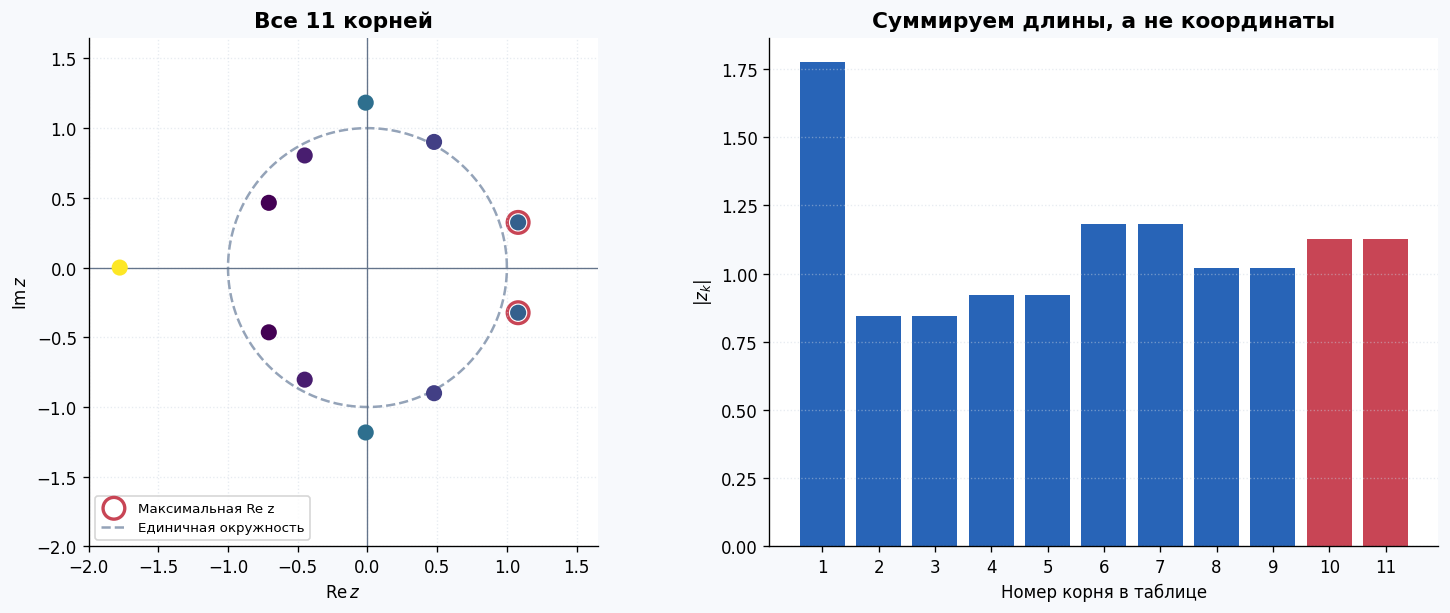

In [11]:
x=sp.symbols('x')
p=x**11+x**10+x**8-2*x**7-x**5+x**4+2*x**2+2*x+2
coeff=np.array([1,1,0,1,-2,0,-1,1,0,2,2,2],dtype=float)
roots_hp=sp.nroots(p,n=40,maxsteps=300)
roots26=np.array(sorted([complex(z) for z in roots_hp],key=lambda z:(z.real,z.imag)))
assert len(roots26)==11
for k,z in enumerate(roots26,1):print(f'z{k:02d} = {fmt(z,10)}')
sum_moduli=float(np.sum(abs(roots26)));max_real=float(np.max(roots26.real))
print(f'\nСумма модулей = {sum_moduli:.12f}')
print(f'Максимальная действительная часть = {max_real:.12f}')

residuals=abs(np.polyval(coeff,roots26))
scales=np.polyval(abs(coeff),abs(roots26))
roots_np=np.roots(coeff)
distance_matrix=abs(roots26[:,None]-roots_np[None,:])
assert np.all(np.min(distance_matrix,axis=1)<1e-10)
assert len(set(np.argmin(distance_matrix,axis=1)))==11
assert np.max(residuals/scales)<1e-12
assert np.isclose(sum(roots26),-1,atol=1e-12)
assert np.isclose(np.prod(roots26),-2,atol=1e-12)
assert max(min(abs(roots26-z.conjugate())) for z in roots26)<1e-12
print(f'Максимальная абсолютная невязка: {max(residuals):.2e}')
print(f'Максимальная относительная невязка: {max(residuals/scales):.2e}')
print('Виет: сумма =',fmt(sum(roots26)),', произведение =',fmt(np.prod(roots26)))
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
axes[0].scatter(roots26.real,roots26.imag,s=75,c=abs(roots26),cmap='viridis',zorder=3)
right=roots26[np.isclose(roots26.real,max_real)]
axes[0].scatter(right.real,right.imag,s=170,facecolors='none',edgecolors=RED,lw=2,label='Максимальная Re z')
t=np.linspace(0,2*np.pi,500)
axes[0].plot(np.cos(t),np.sin(t),'--',color='#94a3b8',label='Единичная окружность')
axes[0].legend(fontsize=8,loc='lower left')
plane(axes[0],'Все 11 корней',(-2,1.65))
axes[1].bar(np.arange(1,12),abs(roots26),color=[RED if np.isclose(z.real,max_real) else BLUE for z in roots26])
axes[1].set(xlabel='Номер корня в таблице',ylabel=r'$|z_k|$',title='Суммируем длины, а не координаты',xticks=np.arange(1,12))
axes[1].grid(axis='y',ls=':')
finish(fig,'task_2_6_polynomial')


**Ответ:**
$$\boxed{\sum_{k=1}^{11}|z_k|\approx11.973384469712,\qquad
\max_k\operatorname{Re}z_k\approx1.080601737358.}$$
Максимум достигается у **двух** сопряжённых корней $1.080601737358\pm0.323893118840i$. Формулировка в единственном числе не меняет требуемое значение действительной части.


<a id="task27"></a>
## 2.7. Обобщённые биномиальные коэффициенты

### a) Найти $C_{1+i}^{1-i}$

Подставляем **нижний индекс** $z=1+i$ и **верхний** $w=1-i$:
$$z+1=2+i,\quad w+1=2-i,\quad z-w+1=1+2i.$$
Значит,
$$\boxed{C_{1+i}^{1-i}=\frac{\Gamma(2+i)}{\Gamma(2-i)\Gamma(1+2i)}
\approx4.367449140640+4.851629765158i.}$$

### b) Найти его главный аргумент

Число находится в I четверти. Используем `atan2`:
$$\boxed{\operatorname{Arg}C_{1+i}^{1-i}\approx0.837869\ \text{рад}\approx48.0064^\circ.}$$


C = 4.367449140640 +4.851629765158i
Arg C = 0.837869369550 рад = 48.006378659°


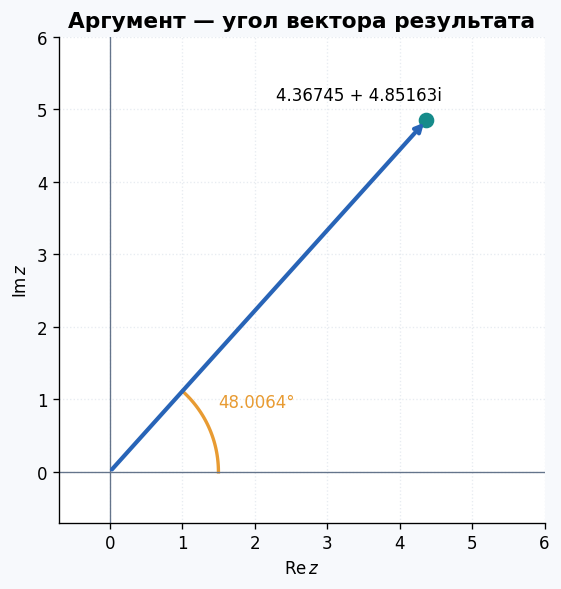

In [12]:
z0,w0=1+1j,1-1j
binom_value=gamma(z0+1)/(gamma(w0+1)*gamma(z0-w0+1))
print('C =',fmt(binom_value,12))
print(f'Arg C = {np.angle(binom_value):.12f} рад = {np.degrees(np.angle(binom_value)):.9f}°')
assert np.isclose(binom_value,4.367449140640+4.851629765158j,atol=1e-10)
fig,ax=plt.subplots(figsize=(6.3,4.8),layout='constrained')
ax.annotate('',(binom_value.real,binom_value.imag),(0,0),arrowprops=dict(arrowstyle='->',color=BLUE,lw=2.5))
ax.scatter(binom_value.real,binom_value.imag,s=70,color=TEAL)
tt=np.linspace(0,np.angle(binom_value),100)
ax.plot(1.5*np.cos(tt),1.5*np.sin(tt),color=ORANGE,lw=2)
ax.text(1.5,.9,'48.0064°',color=ORANGE)
ax.annotate('4.36745 + 4.85163i',(binom_value.real,binom_value.imag),xytext=(-90,12),textcoords='offset points')
plane(ax,'Аргумент — угол вектора результата',(-.7,6))
finish(fig,'task_2_7_value')


### c) Линии уровня $\operatorname{Arg}C_z^{1/z}=\mathrm{const}$

Верхний индекс здесь именно **$1/z$**, а не $1$ и не $z$. Подставим $w=1/z$:
$$F(z)=C_z^{1/z}=\frac{\Gamma(z+1)}{\Gamma(1+1/z)\Gamma(z-1/z+1)}.$$
Определяем функцию на сетке $z=x+iy$. Цвет показывает главный аргумент, линии соединяют точки с одинаковой фазой. Вычисления ведём через `loggamma`, чтобы не переполнялись промежуточные значения.

**Особенности:** $z=0$ исключён из-за $1/z$. Гамма-функция имеет полюса в неположительных целых; знаменатель при продолжении может давать нули $F$, где аргумента тоже нет. Точки, в которых отдельные гамма-множители сингулярны, консервативно маскируем; возможное устранение отдельных особенностей здесь не исследуется. Серый центральный диск $|z|<0.065$ скрывает колебания мельче шага сетки, а не обозначает доказанную область неопределённости.

Чтобы **не рисовать ложные линии на скачке $-\pi\leftrightarrow\pi$**, уровень $\theta$ строим как $\operatorname{Im}(e^{i(\operatorname{Im}L-\theta)})=0$ только там, где $\operatorname{Re}(e^{i(\operatorname{Im}L-\theta)})>0$. Второе условие отбрасывает противоположный луч. Рядом с центром даже такой график ограничен разрешением.


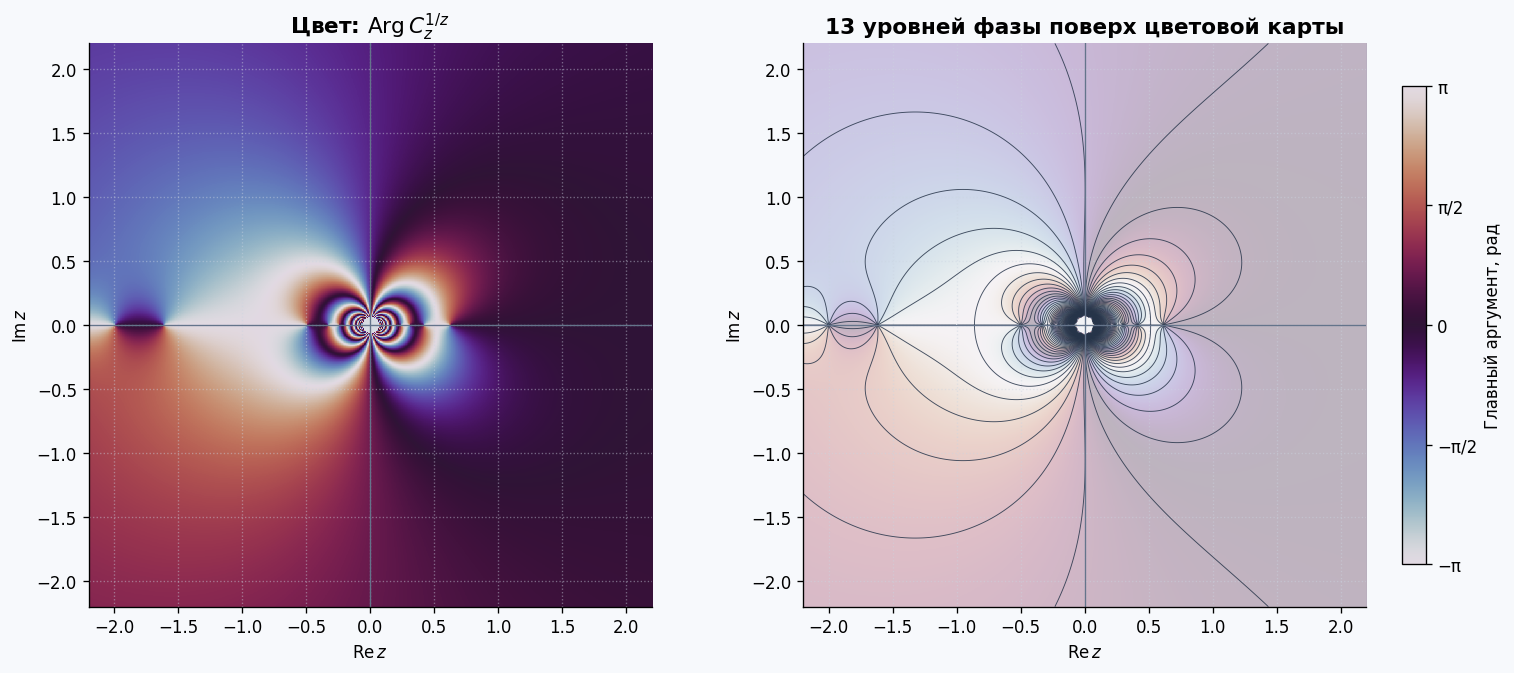

Фазы прямого и логарифмического вычислений совпали в контрольных точках.


In [13]:
axis27=np.linspace(-2.2,2.2,881)
X27,Y27=np.meshgrid(axis27,axis27);Z27=X27+1j*Y27
def gamma_pole(a):
    return (abs(a.imag)<1e-12)&(a.real<=0)&(abs(a.real-np.rint(a.real))<1e-10)

with np.errstate(divide='ignore',invalid='ignore',over='ignore'):
    W27=1/Z27
    args27=[Z27+1,W27+1,Z27-W27+1]
    L27=loggamma(args27[0])-loggamma(args27[1])-loggamma(args27[2])
    bad27=(abs(Z27)<.065)|~np.isfinite(L27)
    for arg in args27:bad27 |= gamma_pole(arg)
    phase27=np.ma.array(np.angle(np.exp(1j*L27.imag)),mask=bad27)

# Сверка устойчивого способа с прямым вычислением вдали от особенностей.
probe=np.array([.7+.4j,-.5+.7j,1.2-.6j])
direct=gamma(probe+1)/(gamma(1+1/probe)*gamma(probe-1/probe+1))
log_value=loggamma(probe+1)-loggamma(1+1/probe)-loggamma(probe-1/probe+1)
assert np.allclose(np.exp(1j*np.angle(direct)),np.exp(1j*log_value.imag),atol=1e-12)

fig,axes=plt.subplots(1,2,figsize=(13,5.5),layout='constrained')
phase_cmap=plt.get_cmap('twilight').copy();phase_cmap.set_bad('#d8dce3')
image27=axes[0].imshow(phase27,origin='lower',extent=[-2.2,2.2,-2.2,2.2],
                     cmap=phase_cmap,vmin=-np.pi,vmax=np.pi,interpolation='nearest')
axes[1].imshow(phase27,origin='lower',extent=[-2.2,2.2,-2.2,2.2],
               cmap=phase_cmap,vmin=-np.pi,vmax=np.pi,alpha=.32,interpolation='nearest')
levels27=np.linspace(-np.pi,np.pi,13,endpoint=False)
for theta in levels27:
    rotated=np.exp(1j*(L27.imag-theta))
    level_field=np.ma.array(rotated.imag,mask=bad27|(rotated.real<=0))
    axes[1].contour(X27,Y27,level_field,levels=[0],colors=['#263449'],linewidths=.55,alpha=.85)
plane(axes[0],r'Цвет: $\operatorname{Arg}C_z^{1/z}$',(-2.2,2.2))
plane(axes[1],'13 уровней фазы поверх цветовой карты',(-2.2,2.2))
cb=fig.colorbar(image27,ax=list(axes),shrink=.85,pad=.025,ticks=[-np.pi,-np.pi/2,0,np.pi/2,np.pi])
cb.ax.set_yticklabels(['−π','−π/2','0','π/2','π']);cb.set_label('Главный аргумент, рад')
finish(fig,'task_2_7_phase')
print('Фазы прямого и логарифмического вычислений совпали в контрольных точках.')


<a id="task28"></a>
## 2.8. Корень из единицы и определитель

Корни 14-й степени из единицы равны $e^{2\pi ik/14}$. Положительная мнимая часть соответствует $k=1,\ldots,6$. Среди этих точек самая правая имеет наименьший положительный угол:
$$\boxed{\lambda=e^{i\pi/7}=\cos(\pi/7)+i\sin(\pi/7).}$$

Для $A=\begin{pmatrix}7&5\\6&2\end{pmatrix}$ получаем
$$\det(A+\lambda I)=(7+\lambda)(2+\lambda)-30=\lambda^2+9\lambda-16.$$
Следовательно,
$$\boxed{\operatorname{Re}\det(A+\lambda I)=\cos(2\pi/7)+9\cos(\pi/7)-16
\approx-7.267790387019,}$$
$$\boxed{\operatorname{Im}\det(A+\lambda I)=\sin(2\pi/7)+9\sin(\pi/7)
\approx4.686785134526.}$$


λ = 0.900968867902 +0.433883739118i
det(A + λI) = -7.267790387019 +4.686785134526i


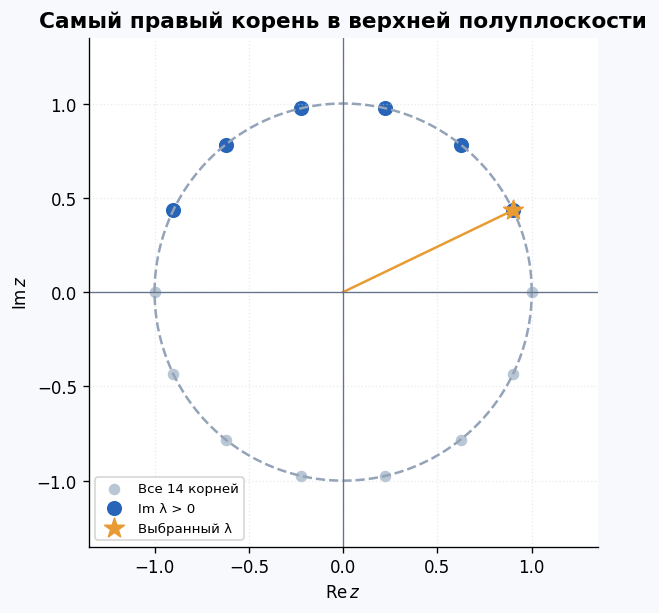

In [14]:
lambda28=np.exp(1j*np.pi/7)
A28=np.array([[7,5],[6,2]],dtype=complex)
det28=lambda28**2+9*lambda28-16
assert np.isclose(np.linalg.det(A28+lambda28*np.eye(2)),det28)
assert np.isclose(lambda28**14,1)
print('λ =',fmt(lambda28,12))
print('det(A + λI) =',fmt(det28,12))
roots14=all_roots(1+0j,14)
upper=roots14[roots14.imag>1e-10]
assert np.isclose(lambda28.real,max(upper.real))
fig,ax=plt.subplots(figsize=(6.4,5),layout='constrained')
t=np.linspace(0,2*np.pi,500);ax.plot(np.cos(t),np.sin(t),'--',color='#94a3b8')
ax.scatter(roots14.real,roots14.imag,s=35,color='#b9c6d4',label='Все 14 корней')
ax.scatter(upper.real,upper.imag,s=65,color=BLUE,label='Im λ > 0')
ax.scatter(lambda28.real,lambda28.imag,s=150,color=ORANGE,marker='*',zorder=5,label='Выбранный λ')
ax.plot([0,lambda28.real],[0,lambda28.imag],color=ORANGE)
ax.legend(loc='lower left',fontsize=8)
plane(ax,'Самый правый корень в верхней полуплоскости',(-1.35,1.35))
finish(fig,'task_2_8_determinant')


<a id="task29"></a>
## 2.9*. Небольшое исследование: множества Жюлиа

### a–b) Что исследуем и как устроена программа

Определения, различие $J_c$ и $K_c$, а также два метода построения разобраны в теории. Здесь реализуем их самостоятельно на Python. Для чтения: [Julia set, Wikipedia](https://en.wikipedia.org/wiki/Julia_set); математическое обоснование обратных итераций — [Stankewitz–Sumi](https://arxiv.org/abs/1312.1457).

Программа работает с **целой сеткой** комплексных стартов. На каждом шаге обновляет только активные точки и записывает номер первой итерации выхода. Это быстрее двух вложенных Python-циклов по пикселям. Ориентация изображения задаётся `origin='lower'`; прямоугольник `extent` совпадает с реальными координатами сетки.

### в) $f_c(z)=z^2+c$ для $c=-0.1+0.65i$ и $c=0.28+0.009i$

Радиус ухода $R=2$ допустим для обоих параметров. Используем 800 итераций и сетку $720\times720$. Можно увеличить `resolution` и `max_iter` для детализации; это увеличит время работы. Дополнительно посмотрим на первые шаги двух отдельных орбит, чтобы связать фрактальную картинку с простой формулой.


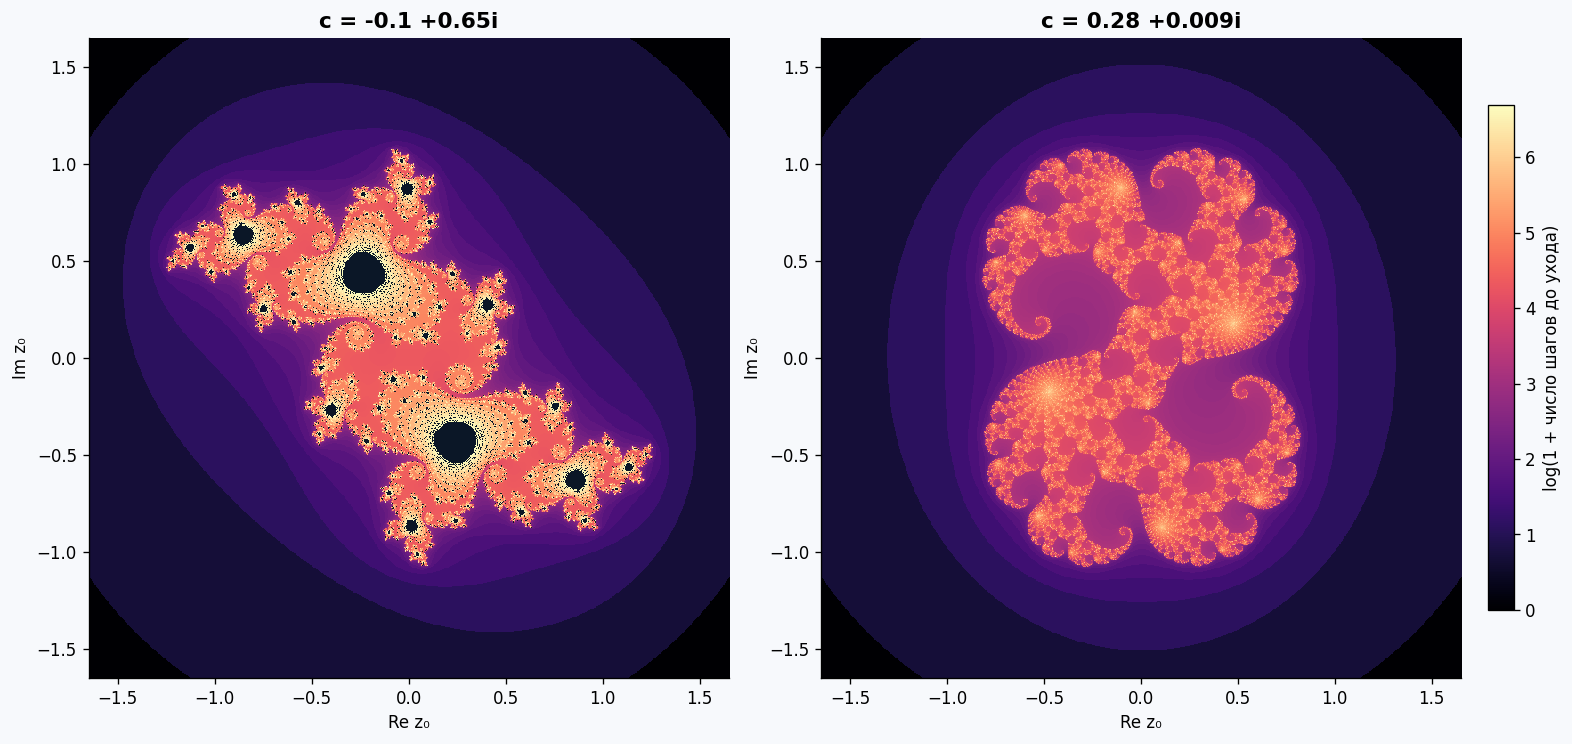

Тёмные точки не ушли за 800 шагов; это приближение заполненного множества.


In [15]:
def quadratic_escape(c, resolution=720, max_iter=800, window=(-1.65,1.65,-1.65,1.65)):
    xmin,xmax,ymin,ymax=window
    xx=np.linspace(xmin,xmax,resolution);yy=np.linspace(ymin,ymax,resolution)
    z=xx[None,:]+1j*yy[:,None]
    z=z.copy()
    active=abs(z)<=2
    # 0 означает, что старт уже вне допустимого радиуса.
    times=np.zeros(z.shape,dtype=np.int32)
    times[active]=max_iter
    for n in range(1,max_iter+1):
        z[active]=z[active]**2+c
        escaped=active&(abs(z)>2)
        times[escaped]=n
        active[escaped]=False
        if not active.any():break
    return times,active,window

cs=[-.1+.65j,.28+.009j]
fig,axes=plt.subplots(1,2,figsize=(13,6),layout='constrained')
cmap_julia=plt.get_cmap('magma').copy();cmap_julia.set_bad('#0b1727')
escape_results=[]
for ax,c in zip(axes,cs):
    times,inside,window=quadratic_escape(c)
    escape_results.append((times,inside))
    # log1p делает детали раннего и позднего ухода одновременно видимыми.
    field=np.ma.array(np.log1p(times),mask=inside)
    im=ax.imshow(field,origin='lower',extent=window,cmap=cmap_julia,
                 vmin=0,vmax=np.log1p(800),interpolation='nearest')
    ax.set(xlabel='Re z₀',ylabel='Im z₀',title=f'c = {c.real:g} {c.imag:+g}i')
    ax.set_aspect('equal')
cb=fig.colorbar(im,ax=list(axes),shrink=.78,pad=.02)
cb.set_label('log(1 + число шагов до ухода)')
finish(fig,'task_2_9_quadratic_julia')
print('Тёмные точки не ушли за 800 шагов; это приближение заполненного множества.')


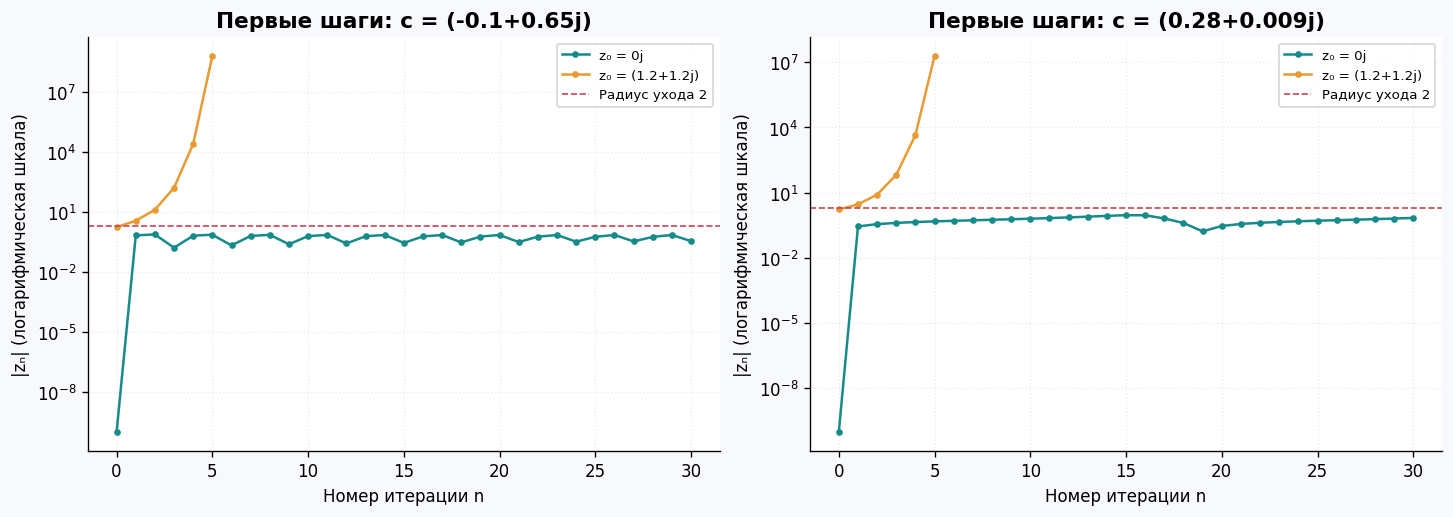

In [16]:
def orbit(c,z0,steps=30):
    values=[complex(z0)]
    for _ in range(steps):
        if abs(values[-1])>1e6:break
        values.append(values[-1]**2+c)
    return np.array(values)

fig,axes=plt.subplots(1,2,figsize=(12,4.2),layout='constrained')
for ax,c in zip(axes,cs):
    for start,color in [(0j,TEAL),(1.2+1.2j,ORANGE)]:
        values=orbit(c,start)
        ax.semilogy(np.arange(len(values)),np.maximum(abs(values),1e-10),'o-',ms=3,color=color,label=f'z₀ = {start}')
    ax.axhline(2,color=RED,ls='--',lw=1,label='Радиус ухода 2')
    ax.set(title=f'Первые шаги: c = {c}',xlabel='Номер итерации n',ylabel='|zₙ| (логарифмическая шкала)')
    ax.legend(fontsize=8);ax.grid(True,ls=':')
finish(fig,'task_2_9_orbits')


### г) Рациональные функции $f_1(z)=\dfrac{iz^5-1}{z^5-i}$ и $f_2(z)=\dfrac{z^2+i}{1-z^2}$

Для обратных итераций аналитически найдём прообразы:
$$f_1(z)=w\iff(w-i)z^5=iw-1\iff
z^5=\frac{iw-1}{w-i},$$
$$f_2(z)=w\iff(w+1)z^2=w-i\iff
z^2=\frac{w-i}{w+1}.$$
В первом случае на каждом шаге выбираем один из пяти корней, во втором — один из двух. Деление на ноль соответствует прообразу $\infty$. Код использует однородные координаты $(a:b)$, где $z=a/b$: так бесконечность $b=0$ обрабатывается без фиктивной замены большим числом.

Для $f_1$ обратное соотношение — $(ia-b:a-ib)$ до извлечения пятого корня, для $f_2$ — $(a-ib:a+b)$ до квадратного корня. После извлечения корней нормируем пару, что не меняет точку сферы. `seed` фиксирован для воспроизводимости.

На рисунках показаны **точки множества Жюлиа**, полученные обратными итерациями. Светлые области — места, не покрытые выборкой; они не объявляются бассейнами притяжения. Цвет и плотность поэтому могут отличаться от примера в PDF, где использовано другое раскрашивание.


$f_1(z)=(iz^5-1)/(z^5-i)$: 399,360 точек; окно [−1.8,1.8] × [−1.8,1.8].
$f_2(z)=(z^2+i)/(1-z^2)$: 819,200 точек; окно [−2.4,2.4] × [−2.4,2.4].


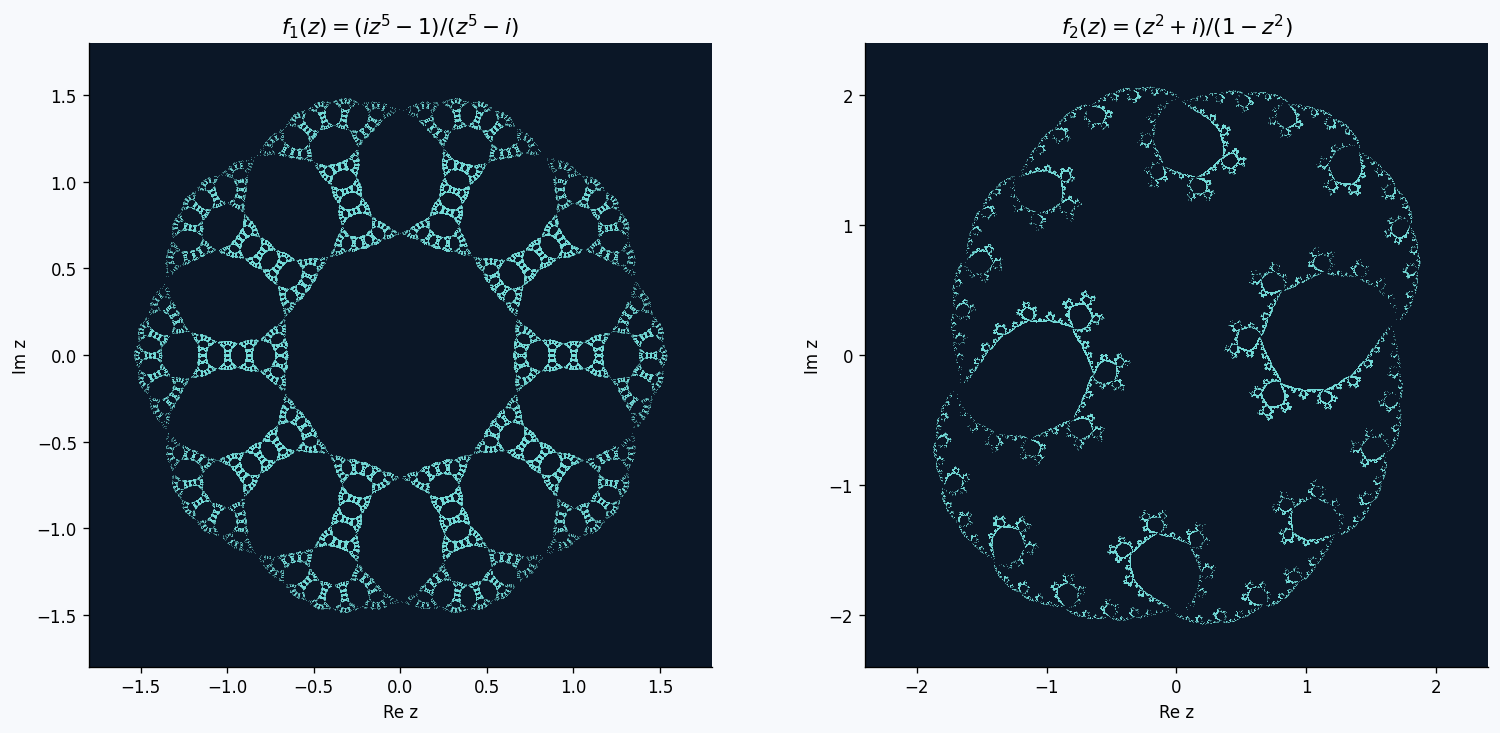

In [17]:
def backward_julia(kind, chains=1536, keep=260, burn=90, seed=7):
    rng=np.random.default_rng(seed)
    a=rng.normal(size=chains)+1j*rng.normal(size=chains)
    b=np.ones(chains,dtype=complex)
    samples=[]
    degree=5 if kind==1 else 2
    for step in range(burn+keep):
        if kind==1:
            numerator,denominator=1j*a-b,a-1j*b
        else:
            numerator,denominator=a-1j*b,a+b
        k=rng.integers(0,degree,size=chains)
        # Произвольные согласованные корни числителя и знаменателя;
        # случайный множитель перебирает все прообразы их отношения.
        a=np.abs(numerator)**(1/degree)*np.exp(1j*(np.angle(numerator)+2*np.pi*k)/degree)
        b=np.abs(denominator)**(1/degree)*np.exp(1j*np.angle(denominator)/degree)
        scale=np.maximum(abs(a),abs(b))
        assert np.all(scale>0)
        a/=scale;b/=scale
        if step>=burn:
            finite=abs(b)>1e-14
            samples.append(a[finite]/b[finite])
    return np.concatenate(samples)

# Проверяем обратные формулы на произвольных конечных точках.
test_w=np.array([.3+.4j,-.7+.2j,2-.3j])
for w in test_w:
    rr1=all_roots((1j*w-1)/(w-1j),5)
    rr2=all_roots((w-1j)/(w+1),2)
    assert np.allclose((1j*rr1**5-1)/(rr1**5-1j),w)
    assert np.allclose((rr2**2+1j)/(1-rr2**2),w)
julia1=backward_julia(1,seed=25)
julia2=backward_julia(2,chains=2048,keep=400,seed=26)
fig,axes=plt.subplots(1,2,figsize=(13,6),layout='constrained')
titles=[r'$f_1(z)=(iz^5-1)/(z^5-i)$',r'$f_2(z)=(z^2+i)/(1-z^2)$']
for ax,points,title,win in zip(axes,[julia1,julia2],titles,[1.8,2.4]):
    ax.set_facecolor('#0b1727')
    ax.scatter(points.real,points.imag,s=.22,color='#77dfdc',alpha=.4,linewidths=0,rasterized=True)
    ax.set(xlim=(-win,win),ylim=(-win,win),xlabel='Re z',ylabel='Im z',title=title)
    ax.set_aspect('equal')
    print(f'{title}: {len(points):,} точек; окно [−{win},{win}] × [−{win},{win}].')
finish(fig,'task_2_9_rational_julia')


### Краткие наблюдения и границы эксперимента

- Параметр $c$ в квадратном отображении меняет расположение крупных областей и тонких ветвей. График времени ухода показывает не только границу, но и скорость расходимости соседних орбит.
- Для рациональных функций обратные прообразы создают повторяющиеся структуры: пять возможных ветвей у $f_1$ и две у $f_2$. Рисунок сам по себе не доказывает связность, размерность или принадлежность точки множеству.
- Чтобы проверить устойчивость картинки, можно увеличить сетку и число шагов для квадратных функций; для рациональных — `chains`, `keep`, `burn`, а также поменять `seed`. Крупные черты должны сохраняться, а мелкие детали уточняться.
- Пример кода в листке смешивает квадратное и рациональное отображения и использует несовпадающие пределы сетки и `extent`. Здесь для каждого отображения выбраны подходящий метод и реальные координаты рисунка.


<a id="task210a"></a>
## 2.10-I*. Прямая, окружность, парабола и гипербола на сфере Римана

Конкретные уравнения в условии не заданы, поэтому выбираем простые представители. Любую другую кривую можно подставить в ту же функцию `stereo`.

| Кривая | Уравнение на плоскости | Параметризация |
|:--|:--|:--|
| Прямая | $y=1/2$ | $z(t)=t+i/2$, $t\in\mathbb R$ |
| Окружность | $x^2+y^2=1$ | $z(t)=e^{it}$, $0\le t\le2\pi$ |
| Парабола | $y=x^2/2$ | $z(t)=t+it^2/2$, $t\in\mathbb R$ |
| Гипербола | $x^2-y^2=1$ | $z_\pm(t)=\pm\cosh t+i\sinh t$, $t\in\mathbb R$ |

Подставляем $x(t),y(t)$ в формулы стереографической проекции. Например, для прямой $y=1/2$:
$$X=\frac{2t}{t^2+5/4},\quad Y=\frac{1}{t^2+5/4},\quad
Z=\frac{t^2-3/4}{t^2+5/4}.$$
Отсюда $Y=(1-Z)/2$: сферический образ лежит в плоскости $2Y+Z=1$. Пересечение этой плоскости со сферой — окружность через северный полюс. Для единичной окружности сразу $Z=0$: образ совпадает с экватором.

У прямой и параболы оба бесконечных конца стремятся к $N$; у гиперболы к $N$ стремятся все четыре конца двух ветвей. **Самой конечной кривой точка $N$ не принадлежит**: она добавляется при замыкании образа. На рисунке $N$ отмечена как ориентир. Конечный диапазон параметров лишь приближает подход к ней.

Слева в каждой паре показана кривая в ограниченном окне плоскости, справа — её сферический образ для более широкого диапазона параметров.


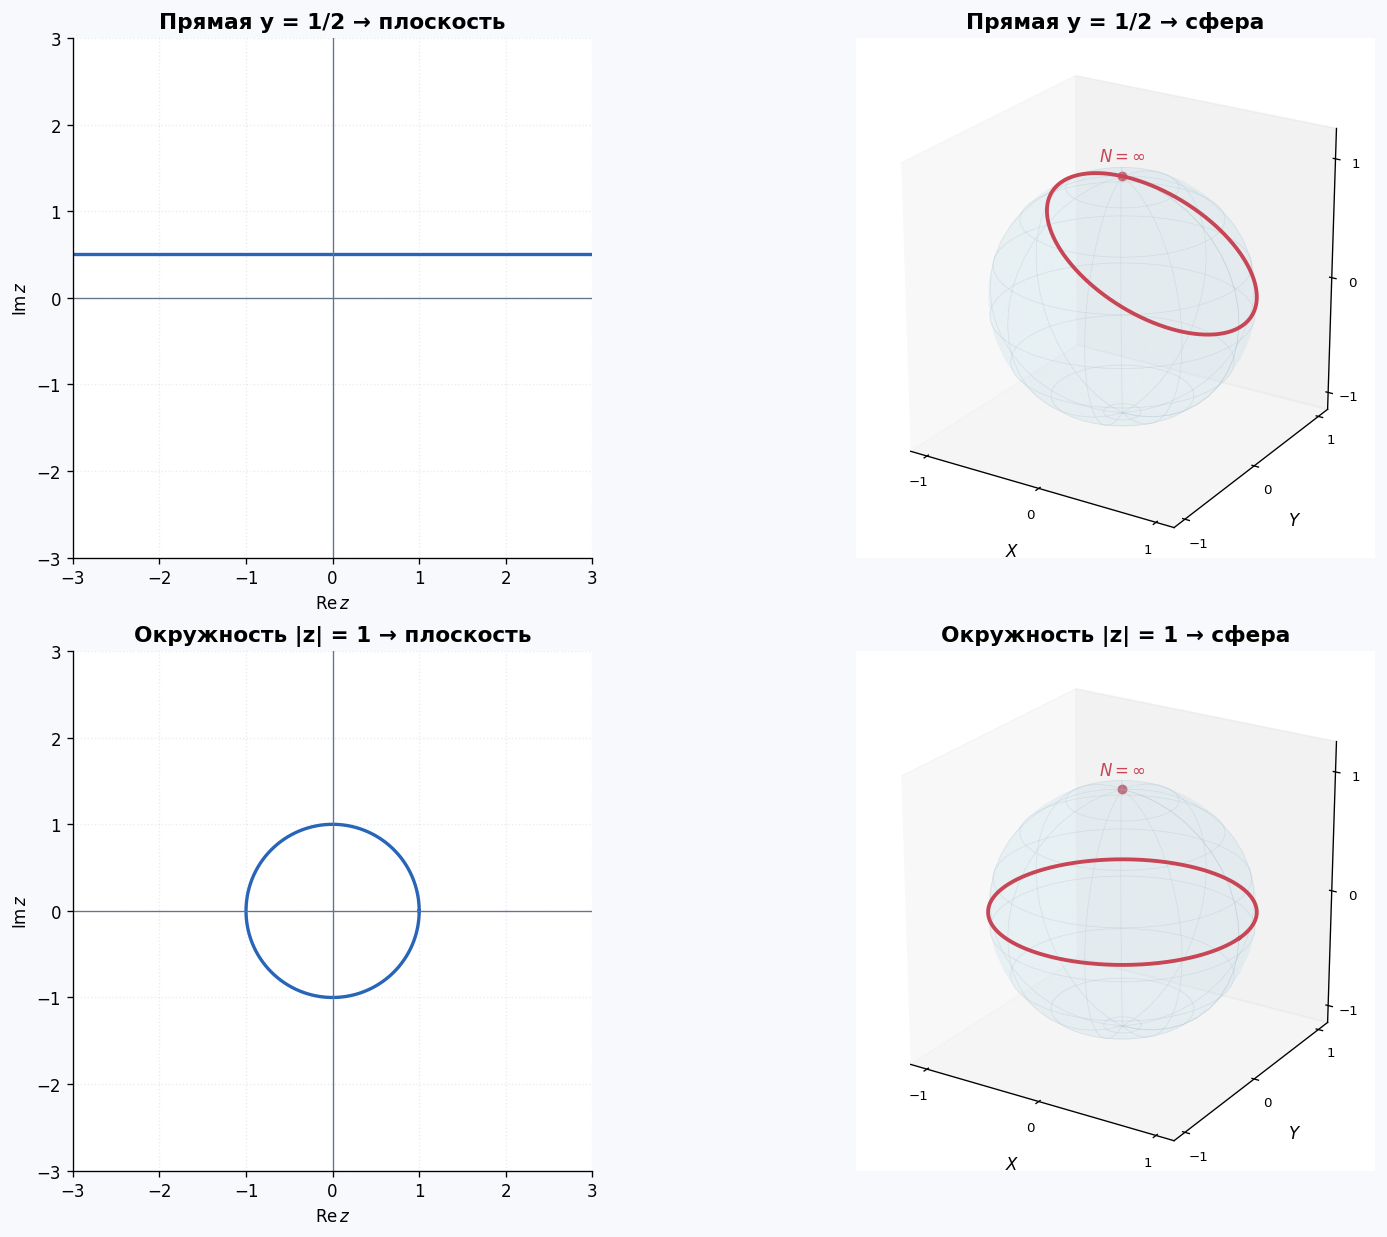

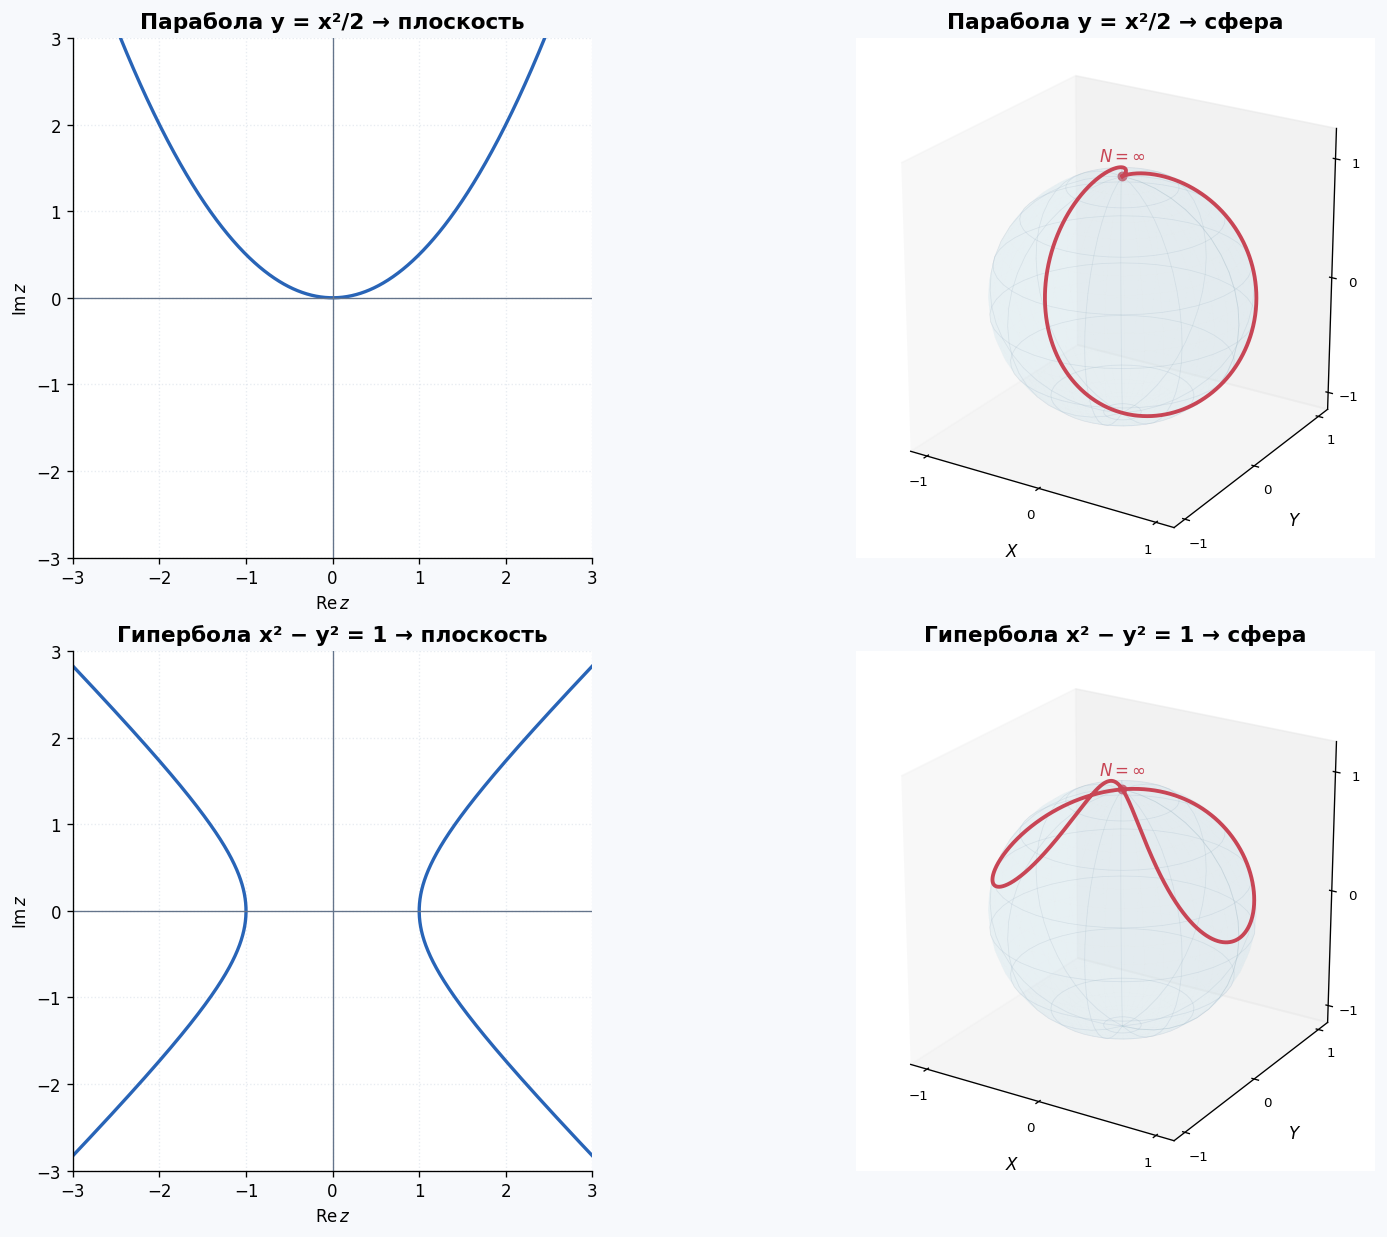

Все вычисленные точки четырёх образов лежат на единичной сфере.


In [18]:
t_long=np.sinh(np.linspace(-5.5,5.5,2800))
angle=np.linspace(0,2*np.pi,1500)
t_hyp=np.linspace(-5.5,5.5,2500)
curves=[('Прямая y = 1/2',[t_long+.5j]),
        ('Окружность |z| = 1',[np.exp(1j*angle)]),
        ('Парабола y = x²/2',[t_long+.5j*t_long**2]),
        ('Гипербола x² − y² = 1',[np.cosh(t_hyp)+1j*np.sinh(t_hyp),
                                  -np.cosh(t_hyp)+1j*np.sinh(t_hyp)])]
for panel in range(2):
    fig=plt.figure(figsize=(13,10.2),layout='constrained')
    for row,(title,branches) in enumerate(curves[panel*2:panel*2+2]):
        axp=fig.add_subplot(2,2,row*2+1)
        axs=fig.add_subplot(2,2,row*2+2,projection='3d')
        sphere(axs,title+' → сфера')
        for branch in branches:
            axp.plot(branch.real,branch.imag,color=BLUE,lw=2)
            sx,sy,sz=stereo(branch)
            assert np.allclose(sx*sx+sy*sy+sz*sz,1,atol=1e-12)
            axs.plot(sx,sy,sz,color=RED,lw=2.3,zorder=5)
        plane(axp,title+' → плоскость',(-3,3))
    finish(fig,f'task_2_10_curves_{panel+1}')
print('Все вычисленные точки четырёх образов лежат на единичной сфере.')


<a id="task210b"></a>
## 2.10-II*. Логарифмическая спираль на сфере Римана

В полярных координатах задано $r=ae^{b\varphi}$. Для обычной логарифмической спирали предполагаем $a>0$, $b\ne0$. Переходим к комплексной форме:
$$z(\varphi)=ae^{b\varphi}(\cos\varphi+i\sin\varphi).$$
Подстановка в стереографическую проекцию даёт
$$\boxed{X=\frac{2ae^{b\varphi}\cos\varphi}{1+a^2e^{2b\varphi}},\quad
Y=\frac{2ae^{b\varphi}\sin\varphi}{1+a^2e^{2b\varphi}},\quad
Z=\frac{a^2e^{2b\varphi}-1}{1+a^2e^{2b\varphi}}.}$$
Удобная устойчивая запись: положим $s=\ln a+b\varphi$. Тогда
$$\boxed{X=\frac{\cos\varphi}{\cosh s},\quad Y=\frac{\sin\varphi}{\cosh s},\quad Z=\tanh s.}$$
Она позволяет не возводить большой радиус в квадрат.

При $b>0$: $\varphi\to-\infty$ даёт $r\to0$ и южный полюс, а $\varphi\to+\infty$ — $r\to\infty$ и северный. При $b<0$ направления меняются. Полюса — предельные точки, не значения при конечном $\varphi$. При $b=0$ вместо спирали получается окружность радиуса $a$ и параллель на сфере; при $a=0$ — только ноль.

В примере ниже $a=0.7$, $b=0.18$. Центральный рисунок показывает общий вид, правый — тот же образ сверху. Цвет кодирует угол $\varphi$ в оборотах.


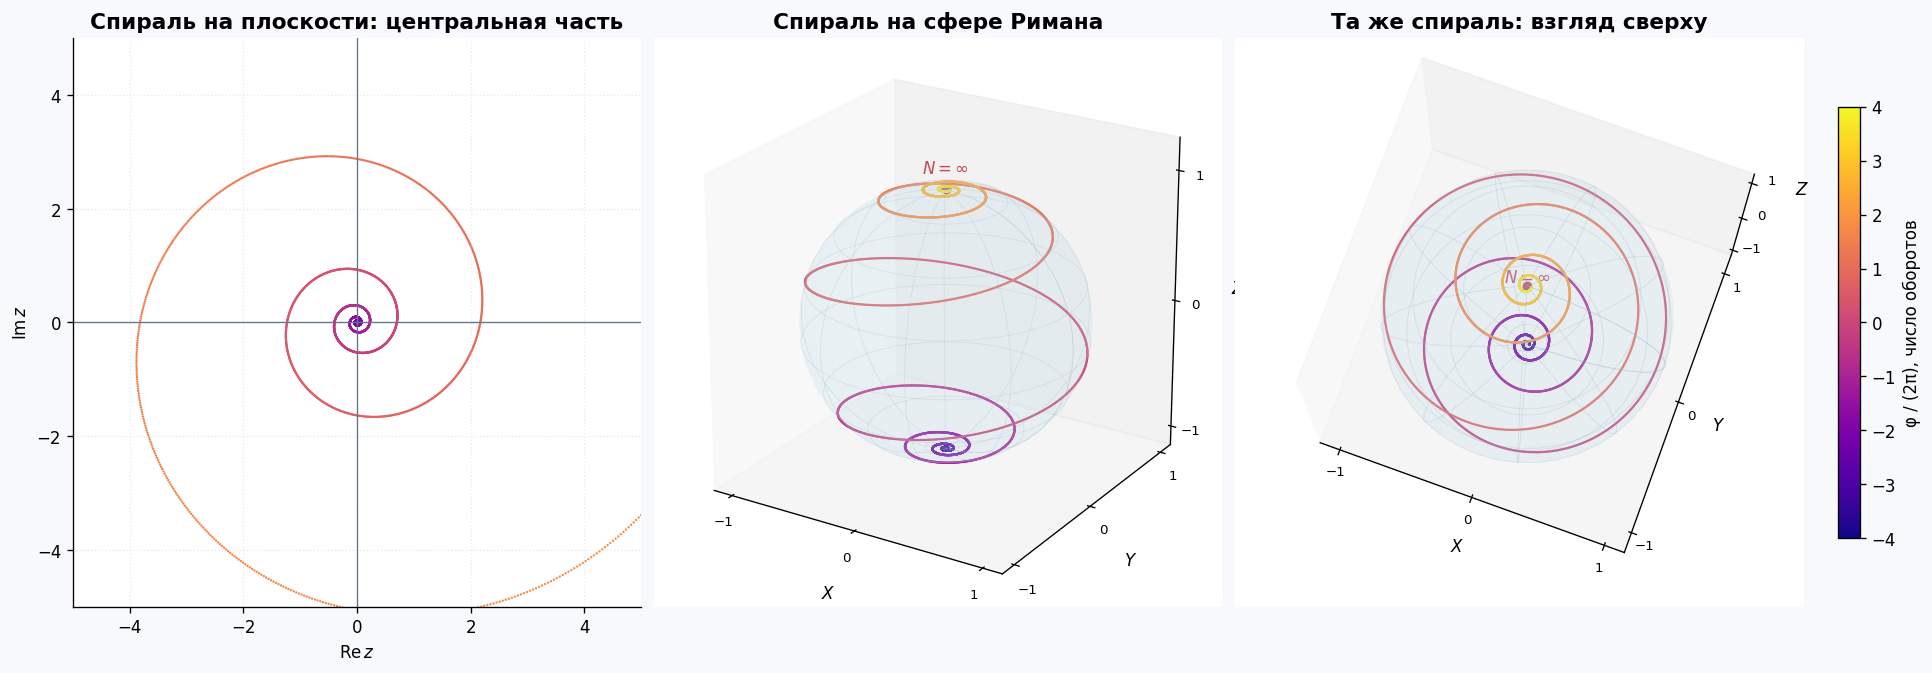

Параметры: a=0.7, b=0.18. Показано 8 оборотов, от φ=−8π до φ=8π.


In [19]:
a_spiral,b_spiral=.7,.18
phi=np.linspace(-8*np.pi,8*np.pi,5000)
radius=a_spiral*np.exp(b_spiral*phi)
z_spiral=radius*np.exp(1j*phi)
s=np.log(a_spiral)+b_spiral*phi
sx=np.cos(phi)/np.cosh(s);sy=np.sin(phi)/np.cosh(s);sz=np.tanh(s)
assert np.allclose(sx*sx+sy*sy+sz*sz,1,atol=1e-12)
assert np.allclose(np.array(stereo(z_spiral)),np.array([sx,sy,sz]),atol=1e-12)
fig=plt.figure(figsize=(16,5.5),layout='constrained')
axp=fig.add_subplot(131)
axs=fig.add_subplot(132,projection='3d')
axt=fig.add_subplot(133,projection='3d')
norm=Normalize(-4,4);cmap=plt.get_cmap('plasma')
turns=phi/(2*np.pi)
axp.scatter(z_spiral.real,z_spiral.imag,c=turns,s=2,cmap=cmap,norm=norm,linewidths=0)
plane(axp,'Спираль на плоскости: центральная часть',(-5,5))
for ax,title in [(axs,'Спираль на сфере Римана'),(axt,'Та же спираль: взгляд сверху')]:
    sphere(ax,title)
    ax.scatter(sx,sy,sz,c=turns,s=2,cmap=cmap,norm=norm,linewidths=0,depthshade=False)
axt.view_init(elev=78,azim=-70)
cb=fig.colorbar(ScalarMappable(norm=norm,cmap=cmap),ax=[axp,axs,axt],shrink=.7,pad=.02)
cb.set_label('φ / (2π), число оборотов')
finish(fig,'task_2_10_spiral')
print(f'Параметры: a={a_spiral}, b={b_spiral}. Показано 8 оборотов, от φ=−8π до φ=8π.')


<a id="summary"></a>
# Часть III. Краткая карта ответов

| Задание | Основной результат |
|:--|:--|
| 2.1 | $10-11i$; $2$; $-64$ и их полярные формы |
| 2.2 | $2^{1/16}e^{i(\pi/32+\pi k/4)}$, $k=0,\ldots,7$ |
| 2.3 | Все корни: 8, 4, 3 и 9 точек соответственно |
| 2.4 a–c | Внутренность эллипса; $x+y<\sqrt2$; $\{0\}$ |
| 2.4 d–f | Открытый правый полукруг; $\varnothing$; область $V<0$, $\sqrt3\vert U\vert \le-V$, $z\ne-i$ |
| 2.5* | Центр $-B/A$, радиус $\sqrt{\vert B\vert ^2-AC}/A$ |
| 2.6 | $\sum\vert z_k\vert \approx11.973384469712$; $\max\operatorname{Re}z_k\approx1.080601737358$ |
| 2.7 | $C\approx4.367449140640+4.851629765158i$; угол $\approx0.837869$ рад; карта фазы $C_z^{1/z}$ |
| 2.8 | $\lambda=e^{i\pi/7}$; определитель $\approx-7.267790387019+4.686785134526i$ |
| 2.9* | Два квадратных и два рациональных множества Жюлиа |
| 2.10-I* | Проекции прямой, окружности, параболы и обеих ветвей гиперболы |
| 2.10-II* | Спираль $z=ae^{b\varphi+i\varphi}$ и её образ на сфере |

Здесь в строке 2.4(f) $U=3x-x^2-y^2-y$, $V=x-3y-3$. Все численные значения округлены; точные формулы приведены в соответствующих разделах.

## Что можно изменить для самостоятельной практики

1. В 2.2 заменить $1+i$ другим числом и степень 8 — на 5: предскажите радиус и поворот многоугольника до запуска.
2. В 2.4(a) изменить сумму расстояний и посмотреть, когда эллипс перестаёт существовать.
3. В 2.9 немного изменить $c$ и сравнить строение границы при одинаковом числе итераций.
4. В 2.10-II изменить знак $b$: проверьте, поменяются ли местами направления движения к полюсам.

## Источник заданий и дополнительные материалы

- П. Е. Рябов, «Задание № 2. Комплексные числа. Геометрия комплексных чисел», предоставленный PDF «Практические занятия Листок 2.pdf», 9 страниц. Условия сверены с визуальным видом PDF; повтор номера 2.10 сохранён с уточняющими обозначениями.
- [NIST DLMF, Gamma Function: Definitions](https://dlmf.nist.gov/5.2) — определение, продолжение и полюса гамма-функции.
- [R. Stankewitz, H. Sumi, Random Backward Iteration Algorithm for Julia Sets](https://arxiv.org/abs/1312.1457) — обоснование метода обратных итераций.
- [Julia set, Wikipedia](https://en.wikipedia.org/wiki/Julia_set) — обзорный материал, упомянутый в задании 2.9.

**Воспроизводимость.** В ноутбуке нет загрузки данных из интернета и абсолютных путей к исходному PDF. Все рисунки строятся из формул; случайные эксперименты используют фиксированные начальные состояния генератора. Проверки в ячейках охватывают точную арифметику, степени корней, геометрические неравенства, независимые способы вычисления корней многочлена, определитель, прообразы рациональных функций и уравнение сферы.
